<a href="https://colab.research.google.com/github/BLTisandwich/OneData-MultiRep/blob/main/multirep_robot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multi-Representation Encoders for LLMs — robot pick-and-place (vision · 3D · proprio time series · speech)

Same question as `multirep_adaptor_harder3d.ipynb`, on a second domain: **under a fixed trainable-parameter budget, is it better to give one encoder one representation, or to split the budget across several small encoders whose tokens are fused into the same K soft tokens of a frozen LLM** (Qwen2.5-0.5B-Instruct)?

**Data.** Randomized Franka Panda pick-and-place episodes in PyBullet, built on `OneData_Omni_EE_OneEpisode_Colab_T4.ipynb` (scene, robot, camera unprojection, espeak-ng speech). Each example is one frame of an episode, seen through four representations of the same moment:

| representation | encoder input | encoder | information only it has |
|---|---|---|---|
| **view** | front + side RGB, 128 px (64 px before 11/22) | small CNN, 4×4 tokens per view (v2: 8×8, see section 4) | the goal disk (flat: removed from the point cloud together with the table) |
| **point** | 768-point colored cloud from both RGB-D cameras, table removed | mini PointNet (+ coordinates relative to the group center), 32 tokens | metric 3D positions |
| **proprio** | last 1 s of joint angles (7), finger opening, EE xyz: a 12 × 11 time series | temporal convs, one token per step | motion |
| **speech** | spoken instruction (espeak-ng, random voice / speed / pitch), 40-bin log-mel | strided temporal convs, 24 tokens | which cube was requested (never in the question text) |

The robot makes mistakes on purpose (missed grasp 20 %, wrong cube 20 %, and in 30 % of episodes a non-requested cube already sits on the goal), so what is held or on the goal is not implied by the instruction. Left out from the original episode: the tactile proxy and event sounds (both derived from the same scripted grasp flag, so they would leak answers) and the cube mesh (always a cube).

Runs on a free Colab T4. Steps: (1) install, (2) config, (3) generate data, (3b) look at the data, (3c) linear probes = shortcut check, (4) models, (5) frozen LLM, (6) train / eval, (7) sweep, (7b) checkpoints, (8) results, (9) router, (10) final table and figures, (11) demo: a new episode with the routed adaptor answering every frame (video).


## 1. Install


In [24]:
# ---------- Install: pybullet (prebuilt), espeak-ng (offline TTS), transformers ----------
import os, sys, shutil, subprocess, importlib.util
if importlib.util.find_spec("pybullet") is None:
    # 1) a prebuilt wheel, if PyPI has one for this Python; 2) otherwise the conda-forge binary via micromamba, as in
    #    OneData_Omni_EE_OneEpisode_Colab_T4.ipynb (pip would compile pybullet from source for many minutes).
    #    The env goes to the END of sys.path, so it cannot shadow Colab's own numpy / torch.
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--only-binary", ":all:", "pybullet"], capture_output=True)
    if r.returncode != 0:
        ver = f"{sys.version_info.major}.{sys.version_info.minor}"
        if not os.path.exists("/opt/pybullet_env"):
            subprocess.run("curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xj bin/micromamba && "
                           f"./bin/micromamba create -y -q -p /opt/pybullet_env -c conda-forge 'python={ver}' pybullet && "
                           "rm -rf bin/micromamba", shell=True, check=True)
        sys.path.append(f"/opt/pybullet_env/lib/python{ver}/site-packages")
import pybullet
if not (shutil.which("espeak-ng") or shutil.which("espeak")):
    subprocess.run("apt-get -qq install -y espeak-ng > /dev/null", shell=True, check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers", "accelerate"], check=True)
print("pybullet", pybullet.__file__, "| espeak:", shutil.which("espeak-ng") or shutil.which("espeak"))


pybullet /opt/pybullet_env/lib/python3.13/site-packages/pybullet.cpython-313-x86_64-linux-gnu.so | espeak: /usr/bin/espeak-ng


## 2. Config


In [25]:
import math, json, os, random, time
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F

CFG = dict(
    seed=0,
    data="robot_v1",
    n_train_eps=600, n_test_eps=100,     # episodes (train / test split by episode, never by frame)
    n_train=7200, n_test=900,            # examples: 1200 / 150 per task, balanced over answers
    p_fail=0.2, p_wrong=0.2,             # robot mistakes: missed grasp / picks a cube that was not requested
    p_distractor=0.3,                    # a non-requested cube already sits on the goal
    n_points=768,                        # colored point cloud (front + side RGB-D, table removed)
    n_views=2,                           # front + side RGB
    view_res=128,                        # px. 64 before 11/22 (a 4.5 cm cube was ~2 px). Cached 64 px data is re-rendered
                                         # from the saved episodes (same frames; only the camera images change); the
                                         # v1 view encoder still sees 64 px (it pools its input), so old runs are unchanged
    proprio_win=12,                      # proprio time series: last 12 frames = 1 s at 12 FPS
    n_mels=40, speech_frames=250,        # spoken instruction: 40-bin log-mel, 20 ms hop, 5 s
    K=16,                                # soft tokens fed to the LLM (fixed for all settings)
    budget=2e6,                          # trainable params per setting (1M before 11/22: four encoders got width 128 only)
    epochs=15, batch_size=64, lr=5e-4, weight_decay=0.01,
    curve_n=300,                         # test examples evaluated after every epoch (learning curve)
    amp=True, q_cond=True, out_scale=True, grad_clip=1.0,   # same adaptor recipe as the 3D notebook
    # ---- modality balancing (section 6). With 1M and plain joint training, "ours" used proprio only: speech /
    # view were never learned although linear probes find their information. balance=False = runs before 11/22.
    balance=True,
    rep_dropout={"proprio": 0.5, "view": 0.2, "point": 0.2, "speech": 0.2},   # (1) per-representation drop prob
                                         #     (multi-rep only, >= 1 kept): the easy proprio is dropped most often
    aux_w=0.5,                           # (2) per-encoder auxiliary answer classifiers (training only; not counted in
                                         #     the budget, dropped at test time), every setting
    ogm_alpha=0.5,                       # (3) OGM-style damping of the dominant encoder's gradient (multi-rep only; 0 = off)
    enc_lr={"proprio": 1.0, "view": 3.0, "point": 2.0, "speech": 3.0},       # (5) per-encoder learning-rate multipliers
    llm_name="Qwen/Qwen2.5-0.5B-Instruct",
)
device = "cuda" if torch.cuda.is_available() else "cpu"
AMP = CFG["amp"] and device == "cuda"

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(CFG["seed"])
print("device:", device)


device: cuda


## 3. Episodes → examples
A scripted kinematic teacher (IK per frame at 12 FPS, smoothstep between waypoints, random speed / heights / home pose) does approach → descend → grasp → lift → carry → lower → release → retract. The grasped cube follows the gripper while held. Only the frames that are used get rendered (front + side camera, 128 px, the point cloud is unprojected from the same depth buffers). Views were pooled to 64 px before 11/22; a 64 px cache is upgraded by re-rendering only the camera images from the saved episodes (same frames, points, speech and answers; a few minutes of CPU), and the v1 view encoder still pools its input to 64 px, so earlier runs stay comparable.

Six tasks, 1200 train / 150 test examples each, balanced over answers. Train and test come from different episodes. The question text never names the requested cube.

| task | question | answers | expected to need |
|---|---|---|---|
| motion | Which way is the gripper moving? | up / down / left / right / forward / backward | **proprio** (every other representation is a single frame) |
| requested | Which color did the speaker ask for? | 6 colors | **speech** |
| held_color | What color is the cube in the gripper? | 6 colors / none (⅓ requested, ⅓ wrong cube, ⅓ empty) | point / view |
| closest | Which cube on the table is closest to the gripper? | 6 colors (half not the requested cube) | point (metric 3D + color) |
| on_goal | Is the requested cube on the goal? | yes / no (no = missed, wrong cube placed, or only another cube on the goal) | view (goal) + speech |
| next_action | What will the robot do next? (0.5 s ahead; half right before a phase change) | 8 phases | proprio + speech + point / view |

Generation runs on the CPU: about 7 s for 200 episodes, ~50 ms per rendered frame (two cameras), so roughly 8–12 min for the full 600 + 100 episodes (~8k frames). The dataset is cached in `robot_data_<data>_s<seed>.pkl`, so re-running the cell after a kernel restart only loads it (`/content` is wiped when the runtime is recycled).

Local check (200 / 50 episodes, linear probes of 3c): motion is solved by proprio only (0.92), requested by speech only (0.98), next_action best by proprio (0.82); on_goal uses the last second of each episode only, because earlier frames let proprio answer "not done yet → no" (0.72 before the fix, 0.56 after).


In [26]:
# ---------- Randomized pick-and-place episodes (PyBullet, scripted kinematic teacher) ----------
# Scene / robot / camera / unprojection conventions follow OneData_Omni_EE_OneEpisode_Colab_T4.ipynb.
import shutil, subprocess, tempfile
from math import gcd, pi
import pybullet as p, pybullet_data
from scipy.io import wavfile
from scipy.signal import resample_poly

COLORS = {"red": (0.86, 0.13, 0.11), "orange": (0.97, 0.52, 0.06), "yellow": (0.95, 0.85, 0.12),
          "blue": (0.12, 0.33, 0.93), "purple": (0.55, 0.22, 0.78), "pink": (0.97, 0.50, 0.72)}
GOAL_RGB = (0.10, 0.80, 0.40)
PHASES = ["approach", "descend", "grasp", "lift", "carry", "lower", "release", "retract"]
MOTIONS = {"up": (2, 1), "down": (2, -1), "left": (1, 1), "right": (1, -1), "forward": (0, 1), "backward": (0, -1)}
# task -> representation(s) we expect it to need: a hypothesis, checked by the probes in 3c and by the sweep
TASKS = {"motion": "proprio", "requested": "speech", "held_color": "point / view", "closest": "point",
         "on_goal": "view + speech", "next_action": "proprio + speech + point/view"}
QUESTIONS = {"motion": "Which way is the gripper moving?",
             "requested": "Which color did the speaker ask for?",
             "held_color": "What color is the cube in the gripper?",
             "closest": "Which cube on the table is closest to the gripper?",
             "on_goal": "Is the requested cube on the goal?",
             "next_action": "What will the robot do next?"}

FPS, EDGE, GOAL_R = 12, 0.045, 0.06
HALF = EDGE / 2
WS_X, WS_Y = (0.38, 0.62), (-0.22, 0.22)      # cube / goal workspace (m), robot base at the origin facing +x
WIN, AHEAD = CFG["proprio_win"], 6             # proprio window (frames); next_action looks 0.5 s ahead
RES, NEAR, FAR = 128, 0.05, 3.0                # render size (views are 2x2 mean-pooled to 64 px)
CAMS = {"front": ([1.35, 0.0, 0.75], [0.45, 0.0, 0.08]), "side": ([0.50, -1.25, 0.70], [0.45, 0.0, 0.08])}
PC_CENTER, PC_SCALE = np.array([0.45, 0.0, 0.20]), 0.40    # point cloud normalization
EE_LINK, FINGERS, REST = 11, (9, 10), [0.0, -0.35, 0.0, -2.2, 0.0, 1.9, 0.79]   # link 11 = panda_grasptarget

def make_sim():
    if p.isConnected(): p.disconnect()
    p.connect(p.DIRECT); p.setAdditionalSearchPath(pybullet_data.getDataPath())
    S = dict(plane=p.loadURDF("plane.urdf", [0, 0, -0.001]),
             robot=p.loadURDF("franka_panda/panda.urdf", [0, 0, 0], useFixedBase=True))
    p.changeVisualShape(S["plane"], -1, rgbaColor=[0.72, 0.74, 0.78, 1])
    S["cubes"] = [p.createMultiBody(0, -1, p.createVisualShape(p.GEOM_BOX, halfExtents=[HALF] * 3), [5, 5, -1])
                  for _ in range(3)]
    S["goal"] = p.createMultiBody(0, -1, p.createVisualShape(p.GEOM_CYLINDER, radius=GOAL_R, length=0.002,
                                                             rgbaColor=[*GOAL_RGB, 1]), [5, 5, -1])
    info = [p.getJointInfo(S["robot"], j) for j in range(7)]
    S["lo"], S["hi"] = [i[8] for i in info], [i[9] for i in info]
    S["proj"] = p.computeProjectionMatrixFOV(fov=50, aspect=1.0, nearVal=NEAR, farVal=FAR)
    S["view"], S["inv_pv"] = {}, {}
    for cam, (eye, tgt) in CAMS.items():
        S["view"][cam] = p.computeViewMatrix(eye, tgt, [0, 0, 1])
        pv = np.asarray(S["proj"]).reshape(4, 4, order="F") @ np.asarray(S["view"][cam]).reshape(4, 4, order="F")
        S["inv_pv"][cam] = np.linalg.inv(pv)
    return S

def set_arm(S, q, finger=None):
    for j, v in enumerate(q): p.resetJointState(S["robot"], j, float(v))
    if finger is not None:
        for j in FINGERS: p.resetJointState(S["robot"], j, float(finger))

def ee_pos(S): return np.array(p.getLinkState(S["robot"], EE_LINK, computeForwardKinematics=True)[4])

def solve_ik(S, xyz, quat, q_prev):
    set_arm(S, q_prev)                                   # warm start from the previous frame
    q = p.calculateInverseKinematics(S["robot"], EE_LINK, list(xyz), quat, lowerLimits=S["lo"], upperLimits=S["hi"],
                                     jointRanges=[h - l for l, h in zip(S["lo"], S["hi"])], restPoses=REST,
                                     maxNumIterations=100, residualThreshold=1e-4)
    return np.array(q[:7])

def _layout(rng):
    """3 cubes + goal disk. Optionally a distractor cube already sits on the goal (then the target is placed next to it)."""
    distract = rng.random() < CFG["p_distractor"]       # decided once: resampling must not change its frequency
    for _ in range(1000):
        cubes = np.column_stack([rng.uniform(*WS_X, 3), rng.uniform(*WS_Y, 3)])
        goal = np.array([rng.uniform(*WS_X), rng.uniform(*WS_Y)])
        if distract: cubes[1] = goal + rng.normal(0, 0.008, 2)
        d = np.linalg.norm(cubes[:, None] - cubes[None], axis=-1)[np.triu_indices(3, 1)]
        dg = np.linalg.norm(cubes - goal, axis=1)
        if d.min() > 0.09 and dg[0] > 0.16 and dg[2] > 0.16 and (distract or dg[1] > GOAL_R + 0.06):
            return cubes, goal, distract
    raise RuntimeError("layout sampling failed")

def gen_episode(S, rng):
    """One scripted pick-and-place: per-frame joint angles, finger opening, EE position, phase and cube poses.
    Cube 0 is the requested one. Robot mistakes: it may pick the wrong cube (cube 2) or miss the grasp (fingers close
    next to the cube, the robot carries on empty), so what is held / on the goal is not implied by the instruction."""
    cubes, goal, distract = _layout(rng)
    colors = [str(c) for c in rng.choice(list(COLORS), 3, replace=False)]
    yaw = rng.uniform(-pi / 4, pi / 4, 3)
    r = rng.random(); fail, wrong = r < CFG["p_fail"], CFG["p_fail"] <= r < CFG["p_fail"] + CFG["p_wrong"]
    pick = 2 if wrong else 0
    miss = rng.uniform(0.04, 0.06) * np.array([np.cos(a := rng.uniform(0, 2 * pi)), np.sin(a)]) if fail else np.zeros(2)
    place = goal + (0.035 * (goal - cubes[1]) / max(np.linalg.norm(goal - cubes[1]), 1e-6) if distract
                    else rng.normal(0, 0.008, 2))
    quat = p.getQuaternionFromEuler([pi, 0.0, yaw[pick] + pi / 4])
    speed = rng.uniform(0.12, 0.22)
    gz, OPEN = HALF + 0.008, 0.04
    shut = 0.0 if fail else HALF                         # fingers stop on the cube, or close completely
    grasp_xy = cubes[pick] + miss
    hover, carry_h, up_h = rng.uniform(0.18, 0.26), rng.uniform(0.20, 0.30), rng.uniform(0.22, 0.32)
    home = np.array([rng.uniform(0.30, 0.42), rng.uniform(-0.12, 0.12), rng.uniform(0.32, 0.40)])
    stops = [(None, home, OPEN, 0.0),
             ("approach", np.r_[grasp_xy, hover], OPEN, None), ("descend", np.r_[grasp_xy, gz], OPEN, None),
             ("grasp", np.r_[grasp_xy, gz], shut, rng.uniform(0.4, 0.6)), ("lift", np.r_[grasp_xy, carry_h], shut, None),
             ("carry", np.r_[place, carry_h], shut, None), ("lower", np.r_[place, gz], shut, None),
             ("release", np.r_[place, gz], OPEN, rng.uniform(0.4, 0.6)), ("retract", np.r_[place, up_h], OPEN, None),
             ("retract", np.r_[place, up_h], OPEN, 0.8)]   # short pause at the end (still "retract")
    t_end, segs = 0.0, []
    for (_, a, fa, _), (ph, b, fb, dur) in zip(stops[:-1], stops[1:]):
        if dur is None: dur = max(0.4, np.linalg.norm(b - a) / speed) * rng.uniform(0.85, 1.15)
        segs.append((t_end, t_end + dur, a, b, fa, fb, PHASES.index(ph))); t_end += dur
    T = int(t_end * FPS) + 1
    q, fing, ee, phase = np.zeros((T, 7)), np.zeros(T), np.zeros((T, 3)), np.zeros(T, int)
    cube_pos = np.tile(np.c_[cubes, np.full(3, HALF)][None], (T, 1, 1))
    held = np.zeros(T, bool); q_prev = np.array(REST); target = np.zeros((T, 3))
    lift_t, release_t = segs[3][0], segs[6][0]          # attached from lift start to release start (success only)
    for k in range(T):
        t = k / FPS
        t0, t1, a, b, fa, fb, ph = next((s for s in segs if t <= s[1] + 1e-9), segs[-1])
        al = np.clip((t - t0) / max(t1 - t0, 1e-6), 0, 1); al = al * al * (3 - 2 * al)     # smoothstep
        target[k] = (1 - al) * a + al * b
        q[k] = q_prev = solve_ik(S, target[k], quat, q_prev)
        fing[k] = (1 - al) * fa + al * fb
        if not fail and PHASES[ph] in ("grasp", "lift", "carry", "lower"): fing[k] = max(fing[k], HALF)
        set_arm(S, q[k]); ee[k] = ee_pos(S); phase[k] = ph
        if not fail and lift_t <= t < release_t:
            held[k] = True; cube_pos[k, pick] = ee[k] + np.r_[cubes[pick] - grasp_xy, HALF - gz]
        elif not fail and t >= release_t:
            cube_pos[k, pick] = np.r_[place, HALF]
    return dict(q=q.astype(np.float32), finger=fing.astype(np.float32), ee=ee.astype(np.float32), phase=phase,
                cube_pos=cube_pos.astype(np.float32), held=held, colors=colors, yaw=yaw, goal=goal, place=place,
                distract=distract, fail=fail, wrong=wrong, pick=pick, quat=quat, T=T,
                ik_err=float(np.linalg.norm(ee - target, axis=1).max()))

def gen_episode_ok(S, rng, tol=0.01):
    """Resample until every frame's IK reaches its target within `tol` (m)."""
    for _ in range(20):
        ep = gen_episode(S, rng)
        if ep["ik_err"] < tol: return ep
    raise RuntimeError(f"IK keeps failing (last error {ep['ik_err']:.3f} m)")

VIEW_POOL = RES // CFG.get("view_res", 64)       # 1 = the full 128 px render, 2 = 64 px (runs before 11/22)
def _pool_view(rgb):
    if VIEW_POOL == 1: return rgb.copy()
    n = RES // VIEW_POOL; return rgb.reshape(n, VIEW_POOL, n, VIEW_POOL, 3).mean((1, 3)).round().astype(np.uint8)

def set_scene(S, ep, k):
    set_arm(S, ep["q"][k], ep["finger"][k])
    for c, body in enumerate(S["cubes"]):
        p.resetBasePositionAndOrientation(body, ep["cube_pos"][k, c].tolist(), p.getQuaternionFromEuler([0, 0, ep["yaw"][c]]))
        p.changeVisualShape(body, -1, rgbaColor=[*COLORS[ep["colors"][c]], 1])
    p.resetBasePositionAndOrientation(S["goal"], [*ep["goal"], 0.001], [0, 0, 0, 1])

def render(S, ep, k, rng):
    """Front + side camera at frame k -> views (2, view_res, view_res, 3) uint8, colored point cloud (table and goal removed)."""
    set_scene(S, ep, k)
    yy, xx = np.mgrid[0:RES, 0:RES]; X, Y = 2.0 * (xx + 0.5) / RES - 1, 1.0 - 2.0 * (yy + 0.5) / RES
    views, pts, rgbs = [], [], []
    for cam in CAMS:
        _, _, rgba, zbuf, seg = p.getCameraImage(RES, RES, S["view"][cam], S["proj"], renderer=p.ER_TINY_RENDERER)
        rgb = np.asarray(rgba, np.uint8).reshape(RES, RES, 4)[..., :3]
        views.append(_pool_view(rgb))
        seg = np.asarray(seg).reshape(RES, RES); z = np.asarray(zbuf, np.float64).reshape(RES, RES)
        fg = (seg >= 0) & (seg != S["plane"]) & (seg != S["goal"])        # support plane removed, as in RGB-D pipelines
        clip = np.stack([X[fg], Y[fg], 2 * z[fg] - 1, np.ones(fg.sum())], -1) @ S["inv_pv"][cam].T
        pts.append(clip[:, :3] / clip[:, 3:]); rgbs.append(rgb[fg] / 255.0)
    pts, rgbs = np.concatenate(pts), np.concatenate(rgbs)
    idx = rng.choice(len(pts), CFG["n_points"], replace=len(pts) < CFG["n_points"])
    return (np.stack(views), ((pts[idx] - PC_CENTER) / PC_SCALE).astype(np.float32), rgbs[idx].astype(np.float32))

def render_views(S, ep, k):
    """Camera images only (the point cloud is untouched)."""
    set_scene(S, ep, k)
    return np.stack([_pool_view(np.asarray(p.getCameraImage(RES, RES, S["view"][cam], S["proj"], renderer=p.ER_TINY_RENDERER)[2],
                                           np.uint8).reshape(RES, RES, 4)[..., :3]) for cam in CAMS])

def ensure_view_res(data, eps):
    """Data cached before 11/22 has 64 px views: re-render just the camera images at CFG['view_res'] from the saved
    episodes. Same frames, points, proprio, speech and answers, so the dataset (and TAG) stays the same.
    Returns True if anything was re-rendered."""
    old = [ex for ex in data if ex["views"].shape[1] != RES // VIEW_POOL]
    if not old: return False
    S = globals().get("SIM") or make_sim(); globals()["SIM"] = S; new, t0 = {}, time.time()
    for ex in old:
        key = (ex["ep"], ex["k"])
        if key not in new: new[key] = render_views(S, eps[ex["ep"]], ex["k"])
        ex["views"] = new[key]
    print(f"  re-rendered {len(new)} frames at {RES // VIEW_POOL} px ({time.time() - t0:.0f}s)")
    return True

def save_pickle(obj, path):
    import pickle; pickle.dump(obj, open(path + ".tmp", "wb")); os.replace(path + ".tmp", path)

# ---------- Spoken instruction: espeak-ng (offline TTS), one fresh utterance per episode ----------
TEMPLATES = ["Pick up the {} cube and put it on the green target.", "Move the {} block onto the goal.",
             "Put the {} cube on the green circle.", "Please place the {} one on the target.",
             "Grab the {} cube and drop it on the green spot."]
VOICES = ["en-us", "en-gb", "en", "en-us+f2", "en-gb+m3", "en+f4", "en-us+m5", "en-gb+f1"]
SR = 16000

def tts(text, rng):
    """espeak-ng with a random voice / speed / pitch -> 16 kHz float waveform. Never replaced by a synthetic beep."""
    cmd = shutil.which("espeak-ng") or shutil.which("espeak")
    if cmd is None: raise RuntimeError("espeak-ng not found: run the install cell (apt-get install espeak-ng)")
    with tempfile.TemporaryDirectory() as d:
        path = os.path.join(d, "s.wav")
        subprocess.run([cmd, "-v", str(rng.choice(VOICES)), "-s", str(int(rng.integers(125, 190))),
                        "-p", str(int(rng.integers(25, 75))), "-w", path, text], check=True, capture_output=True)
        sr, x = wavfile.read(path)
    x = x.astype(np.float32) / 32768.0
    g = gcd(SR, sr); return resample_poly(x, SR // g, sr // g).astype(np.float32)

def _mel_fb(n_fft=400, n_mels=CFG["n_mels"]):
    hz2mel, mel2hz = lambda f: 2595 * np.log10(1 + f / 700), lambda m: 700 * (10 ** (m / 2595) - 1)
    bins = np.floor((n_fft + 1) * mel2hz(np.linspace(0, hz2mel(SR / 2), n_mels + 2)) / SR).astype(int)
    fb = np.zeros((n_mels, n_fft // 2 + 1))
    for m in range(n_mels):
        l, c, r = bins[m:m + 3]
        fb[m, l:c] = (np.arange(l, c) - l) / max(c - l, 1); fb[m, c:r] = (r - np.arange(c, r)) / max(r - c, 1)
    return fb
MEL_FB = _mel_fb()

def log_mel(x, n_fft=400, hop=320, frames=CFG["speech_frames"]):
    """25 ms Hann window, 20 ms hop -> (frames, n_mels) log-mel, zero-padded / cropped to a fixed length."""
    x = np.pad(x, (0, max(0, n_fft - len(x))))
    n = 1 + (len(x) - n_fft) // hop
    fr = np.lib.stride_tricks.as_strided(x, (n, n_fft), (x.strides[0] * hop, x.strides[0])) * np.hanning(n_fft)
    m = np.log(np.abs(np.fft.rfft(fr, axis=1)) ** 2 @ MEL_FB.T + 1e-6)
    out = np.full((frames, m.shape[1]), np.log(1e-6), np.float32); out[:min(n, frames)] = m[:frames]
    return out

# ---------- Episodes -> balanced (frame, task) examples ----------
def _candidates(ep):
    """All (task, frame, answer, (primary key, secondary key)) an episode can provide. Sampling is balanced over the
    primary key, then over the secondary key within it (see build_split)."""
    T, ph, ee, out = ep["T"], ep["phase"], ep["ee"], []
    tgt = ep["colors"][0]
    kind = "fail" if ep["fail"] else "wrong" if ep["wrong"] else "ok"
    for k in range(T):
        out.append(("requested", k, tgt, (tgt, None)))
        if k >= AHEAD:                                   # dominant axis of the last 0.5 s of EE motion
            d = ee[k] - ee[k - AHEAD]
            if np.linalg.norm(d) > 0.03:
                ax = int(np.abs(d).argmax()); a = [m for m, (i, s) in MOTIONS.items() if i == ax and s == np.sign(d[ax])][0]
                out.append(("motion", k, a, (a, None)))
        if PHASES[ph[k]] in ("lift", "carry", "lower"):  # 1/3 requested cube, 1/3 wrong cube, 1/3 empty gripper
            a = "none" if ep["fail"] else ep["colors"][ep["pick"]]; out.append(("held_color", k, a, (kind, a)))
        if not ep["held"][k] and PHASES[ph[k]] in ("approach", "descend", "retract"):
            d = np.linalg.norm(ep["cube_pos"][k] - ee[k], axis=1); o = np.argsort(d)
            if d[o[0]] < 0.75 * d[o[1]]:                 # unambiguous closest cube; half of them not the requested one
                a = ep["colors"][o[0]]; out.append(("closest", k, a, (a == tgt, a)))
        on = np.linalg.norm(ep["cube_pos"][k, 0, :2] - ep["goal"]) < GOAL_R and ep["cube_pos"][k, 0, 2] < EDGE
        if k >= T - FPS:   # last second only (earlier frames would let proprio answer "not done yet" -> no)
            a = "yes" if on else "no"                    # no = missed grasp, or the wrong cube was placed
            out.append(("on_goal", k, a, (a, kind + ("+distractor" if ep["distract"] else ""))))
        if k + AHEAD < T - FPS:                          # half of them right before a phase change
            nxt = PHASES[ph[k + AHEAD]]; out.append(("next_action", k, nxt, (nxt, bool(ph[k + AHEAD] != ph[k]))))
    return out

def _balanced(groups, n, rng):
    """groups: {primary: {secondary: [items]}} -> n items, round-robin over primary keys, then over secondary keys,
    cycling (with reuse only when a group runs out)."""
    prim = sorted(groups, key=str); sec = {k: sorted(groups[k], key=str) for k in prim}
    shuf = {(a, b): [groups[a][b][i] for i in rng.permutation(len(groups[a][b]))] for a in prim for b in sec[a]}
    cnt_p, cnt_s, out = {a: 0 for a in prim}, {key: 0 for key in shuf}, []
    for j in range(n):
        a = prim[j % len(prim)]; b = sec[a][cnt_p[a] % len(sec[a])]; cnt_p[a] += 1
        g = shuf[a, b]; out.append(g[cnt_s[a, b] % len(g)]); cnt_s[a, b] += 1
    return out

def build_split(n_eps, n_per_task, seed, S):
    """Generate n_eps episodes, draw n_per_task examples per task balanced over answers (episode-level split)."""
    rng = np.random.default_rng(seed); t0 = time.time()
    eps = [gen_episode_ok(S, rng) for _ in range(n_eps)]
    t1 = time.time()
    for ep in eps: ep["mel"] = log_mel(tts(str(rng.choice(TEMPLATES)).format(ep["colors"][0]), rng))
    t2 = time.time()
    cand = {}
    for e, ep in enumerate(eps):
        for task, k, a, (k1, k2) in _candidates(ep):
            cand.setdefault(task, {}).setdefault(k1, {}).setdefault(k2, []).append((e, k, a))
    picks = []
    for task in TASKS: picks += [(task, e, k, a) for e, k, a in _balanced(cand[task], n_per_task, rng)]
    cache, data = {}, []
    for task, e, k, a in picks:
        if (e, k) not in cache: cache[e, k] = render(S, eps[e], k, np.random.default_rng([seed, e, k]))
        views, pts, prgb = cache[e, k]
        lo = max(0, k - WIN + 1); win = np.r_[[0] * (WIN - (k - lo + 1)), np.arange(lo, k + 1)].astype(int)
        ep = eps[e]
        proprio = np.c_[ep["q"][win], ep["finger"][win], ep["ee"][win]].astype(np.float32)   # (WIN, 11)
        data.append(dict(task=task, q=QUESTIONS[task], a=a, ep=e, k=k, views=views, points=pts, point_rgb=prgb,
                         proprio=proprio, speech=ep["mel"]))
    order = rng.permutation(len(data)); data = [data[i] for i in order]
    print(f"  {n_eps} episodes {t1 - t0:.0f}s, speech {t2 - t1:.0f}s, {len(cache)} frames rendered {time.time() - t2:.0f}s")
    return data, eps

DATA_PATH = f"robot_data_{CFG['data']}_s{CFG['seed']}.pkl"
if os.path.exists(DATA_PATH):
    import pickle; train_data, test_data, train_eps, test_eps = pickle.load(open(DATA_PATH, "rb"))
    print("loaded", DATA_PATH)
    if ensure_view_res(train_data, train_eps) | ensure_view_res(test_data, test_eps):   # 64 px cache -> view_res
        save_pickle((train_data, test_data, train_eps, test_eps), DATA_PATH)
else:
    SIM = make_sim()
    print("train:"); train_data, train_eps = build_split(CFG["n_train_eps"], CFG["n_train"] // len(TASKS), CFG["seed"], SIM)
    print("test:");  test_data, test_eps = build_split(CFG["n_test_eps"], CFG["n_test"] // len(TASKS), CFG["seed"] + 1, SIM)
    save_pickle((train_data, test_data, train_eps, test_eps), DATA_PATH)
# proprio / speech normalization from the training split only
PROPRIO_MU = np.mean([ex["proprio"] for ex in train_data], (0, 1)); PROPRIO_SD = np.std([ex["proprio"] for ex in train_data], (0, 1)) + 1e-4
MEL_MU = np.mean([ep["mel"] for ep in train_eps]); MEL_SD = np.std([ep["mel"] for ep in train_eps])
print(f"{len(train_data)} train / {len(test_data)} test examples; missed grasp {np.mean([e['fail'] for e in train_eps]):.2f}, "
      f"wrong cube {np.mean([e['wrong'] for e in train_eps]):.2f}, distractor on goal {np.mean([e['distract'] for e in train_eps]):.2f}, "
      f"episode length {np.mean([e['T'] for e in train_eps]) / FPS:.1f}s")
print(test_data[0]["q"], "->", test_data[0]["a"])


loaded robot_data_robot_v1_s0.pkl
7200 train / 900 test examples; missed grasp 0.20, wrong cube 0.19, distractor on goal 0.31, episode length 10.2s
Which color did the speaker ask for? -> yellow


## 3b. Look at the data
Each row is one frame: a high-res render for humans only, then exactly what each encoder receives, and every question asked about that frame. Saves `robot_examples.png`.


In [ ]:
# ---------- Look at the data: what each encoder receives for one frame ----------
import matplotlib.pyplot as plt

def render_hi(S, ep, k, res=320, cam="front"):
    """High-res render for humans only (not a model input)."""
    render(S, ep, k, np.random.default_rng(0))                # sets the scene state
    eye, tgt = CAMS[cam]
    img = p.getCameraImage(res, res, p.computeViewMatrix(eye, tgt, [0, 0, 1]), S["proj"], renderer=p.ER_TINY_RENDERER)[2]
    return np.asarray(img, np.uint8).reshape(res, res, 4)[..., :3]

def show_examples(data, eps, tasks=("next_action", "held_color", "on_goal"), seed=3):
    rng = np.random.default_rng(seed); S = globals().get("SIM") or make_sim()
    exs = [data[i] for i in [rng.choice([j for j, ex in enumerate(data) if ex["task"] == t]) for t in tasks]]
    fig = plt.figure(figsize=(19, 3.9 * len(exs)), layout="constrained")
    for sf, ex in zip(fig.subfigures(len(exs), 1), exs):
        ep = eps[ex["ep"]]; same = [e2 for e2 in data if e2["ep"] == ex["ep"] and e2["k"] == ex["k"]]
        sf.suptitle("   ".join(f"[{e2['task']}] {e2['q']} → {e2['a']}" for e2 in same), x=0.01, ha="left", fontsize=9)
        axs = sf.subplots(1, 6); axs[3].remove(); axs[3] = sf.add_subplot(1, 6, 4, projection="3d")
        ax = axs[0]; ax.imshow(render_hi(S, ep, ex["k"])); ax.axis("off")
        ax.set_title(f"t = {ex['k'] / FPS:.1f}s, phase {PHASES[ep['phase'][ex['k']]]}, requested {ep['colors'][0]}"
                     + ("\nMISSED grasp" if ep["fail"] else "\nWRONG cube picked" if ep["wrong"] else ""), fontsize=8)
        for c, cam in enumerate(CAMS):
            ax = axs[1 + c]; ax.imshow(ex["views"][c]); ax.axis("off"); ax.set_title(f"{cam} view ({ex['views'].shape[1]} px)", fontsize=8)
        ax = axs[3]
        P = ex["points"] * PC_SCALE + PC_CENTER; ax.scatter(P[:, 0], P[:, 1], P[:, 2], c=ex["point_rgb"], s=3, depthshade=False)
        ax.set_title(f"{CFG['n_points']} points (xyz + rgb)", fontsize=8); ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
        ax = axs[4]
        tt = (np.arange(WIN) - WIN + 1) / FPS
        for i, (lbl, col) in enumerate(zip("xyz", ["#2a78d6", "#eb6834", "#1baf7a"])): ax.plot(tt, ex["proprio"][:, 8 + i], color=col, label=f"EE {lbl}")
        ax.plot(tt, ex["proprio"][:, 7] * 5, color="#52514e", ls="--", label="finger x5")
        ax.set_title("proprio window (+ 7 joint angles)", fontsize=8); ax.legend(fontsize=6); ax.set_xlabel("s", fontsize=7)
        ax = axs[5]; ax.imshow(ex["speech"].T, origin="lower", aspect="auto", cmap="magma")
        ax.set_title("spoken instruction (log-mel)", fontsize=8); ax.set_xticks([]); ax.set_yticks([])
    plt.savefig("robot_examples.png", dpi=110, bbox_inches="tight"); plt.show()

show_examples(test_data, test_eps)
print("answer distribution per task (test) and majority-class accuracy:")
for t in TASKS:
    a = [ex["a"] for ex in test_data if ex["task"] == t]; v, c = np.unique(a, return_counts=True)
    print(f"  {t:12s} majority {c.max() / len(a):.2f} | " + ", ".join(f"{x} {n}" for x, n in zip(v, c)))


## 3c. Shortcut check: linear probes per representation (CPU)
Logistic regression on simple features of each representation (pooled pixels, a colored voxel grid, the raw proprio window, a pooled spectrogram). This is a lower bound on what each representation carries, not the adaptor's result; it is here to catch design errors before GPU time: a task solved by the "wrong" representation, or guessable from the majority answer.


In [27]:
# ---------- Which representation carries each answer? Linear probes on simple features (CPU, ~1-2 min) ----------
# A cheap check of the task design before any GPU time: if one representation solves a task it "should not", or the
# answer is guessable without the scene (majority class), the design has a shortcut.
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

def probe_feats(ex, rep):
    if rep == "view":                                          # 2 views, 4x4-pooled to 16x16 RGB
        v = ex["views"].astype(np.float32) / 255; V, H = v.shape[:2]
        return v.reshape(V, 16, H // 16, 16, H // 16, 3).mean((2, 4)).ravel()
    if rep == "point":                                         # 6x6x6 voxel grid: occupancy + mean RGB
        g = np.clip(((ex["points"] + 1) / 2 * 6).astype(int), 0, 5); cell = g[:, 0] * 36 + g[:, 1] * 6 + g[:, 2]
        occ = np.bincount(cell, minlength=216).astype(np.float32)
        col = np.stack([np.bincount(cell, ex["point_rgb"][:, c], 216) for c in range(3)], 1) / np.maximum(occ, 1)[:, None]
        return np.r_[occ / len(cell), col.ravel()]
    if rep == "proprio": return ((ex["proprio"] - PROPRIO_MU) / PROPRIO_SD).ravel()
    if rep == "speech":                                        # log-mel, pooled to 25 time steps
        m = (ex["speech"] - MEL_MU) / MEL_SD; return m.reshape(25, -1, m.shape[1]).mean(1).ravel()

PROBE_REPS = ["view", "point", "proprio", "speech"]
def run_probes(train, test):
    rows = {}
    for task in TASKS:
        tr = [ex for ex in train if ex["task"] == task]; te = [ex for ex in test if ex["task"] == task]
        ytr, yte = [ex["a"] for ex in tr], [ex["a"] for ex in te]
        vals, cnt = np.unique(ytr, return_counts=True)
        row = {"majority": float(np.mean(np.array(yte) == vals[cnt.argmax()]))}
        F_tr = {r: np.stack([probe_feats(ex, r) for ex in tr]) for r in PROBE_REPS}
        F_te = {r: np.stack([probe_feats(ex, r) for ex in te]) for r in PROBE_REPS}
        F_tr["all"] = np.concatenate([F_tr[r] for r in PROBE_REPS], 1); F_te["all"] = np.concatenate([F_te[r] for r in PROBE_REPS], 1)
        for r in PROBE_REPS + ["all"]:
            sc = StandardScaler().fit(F_tr[r])
            clf = LogisticRegression(C=0.05, max_iter=300).fit(sc.transform(F_tr[r]), ytr)
            row[r] = float(np.mean(clf.predict(sc.transform(F_te[r])) == np.array(yte)))
        rows[task] = row; print(f"  {task:12s} " + " ".join(f"{k} {v:.2f}" for k, v in row.items()))
    return rows

import pandas as pd
t0 = time.time(); PROBES = run_probes(train_data, test_data)
probe_df = pd.DataFrame(PROBES).T[["majority"] + PROBE_REPS + ["all"]]
probe_df["expected"] = [TASKS[t] for t in probe_df.index]
display(probe_df.round(2)); print(f"({time.time() - t0:.0f}s)")


  motion       majority 0.17 view 0.48 point 0.39 proprio 0.97 speech 0.15 all 0.85
  requested    majority 0.17 view 0.18 point 0.16 proprio 0.17 speech 0.99 all 0.81
  held_color   majority 0.33 view 0.43 point 0.35 proprio 0.47 speech 0.34 all 0.59
  closest      majority 0.17 view 0.19 point 0.17 proprio 0.23 speech 0.31 all 0.23
  on_goal      majority 0.50 view 0.62 point 0.45 proprio 0.53 speech 0.53 all 0.62
  next_action  majority 0.13 view 0.41 point 0.40 proprio 0.79 speech 0.14 all 0.72


,majority,view,point,proprio,speech,all,expected
motion,0.17,0.48,0.39,0.97,0.15,0.85,proprio
requested,0.17,0.18,0.16,0.17,0.99,0.81,speech
held_color,0.33,0.43,0.35,0.47,0.34,0.59,point / view
closest,0.17,0.19,0.17,0.23,0.31,0.23,point
on_goal,0.50,0.62,0.45,0.53,0.53,0.62,view + speech
next_action,0.13,0.41,0.40,0.79,0.14,0.72,proprio + speech + point/view


(66s)


## 4. Shallow encoders, aggregators (Q-Former / MLP), budget matching
`match_budget` picks one shared width so that **encoders + aggregator + question projection + output projection** hit the target parameter count (LLM excluded). Same adaptor recipe as the 3D notebook: question-conditioned Q-Former (InstructBLIP), per-representation LayerNorm + type embedding, soft tokens scaled to the LLM's embedding RMS.

**Per-representation queries** (`agg="qformer_rep"`, added 11/22). In the 1M sweep the plain Q-Former's 16 shared queries collapsed onto the easy proprio tokens (speech ignored: `requested` 0.17), while the MLP aggregator, which has a fixed slot per representation, used all four (avg 0.71 vs 0.49). Here the K = 16 queries are split evenly (4 per representation) and each group cross-attends only to its own representation's tokens, plus a learned null token it falls back on when that representation is dropped; all queries and the question tokens still share self-attention, so information is exchanged before reaching the LLM. Same parameter count as the plain Q-Former up to the R null tokens.

**Relational fusion** (`fusion="rel"`, added 11/22). After balancing, every fusion model reached ~0.72, but only `held_color` beat the best single representation; `closest` (gripper-to-cube distances) and `on_goal` (requested color × cube on the goal disk) stayed at the level of guessing the requested cube. In the plain design, tokens never see each other: encoders run separately and the Q-Former only takes weighted sums. Two self-attention layers over **all tokens plus the question** now run before the aggregator, so the question and speech tokens can retrieve the tokens they refer to and tokens of different representations can be matched. Attention gets a **relation (spatial) encoding** (relative-position bias as in Point Transformer, Zhao et al., ICCV 2021, and Swin, Liu et al., ICCV 2021): for two tokens in the same space, an MLP of their offset (dx, dy, dz, |d|) adds a per-head bias. The spaces are the 3D world (point-group centers and the proprio EE positions, in the point-cloud frame) and each camera's 4×4 image grid; speech and question tokens have no position. No information is added to any representation: coordinates are only those it already has. `fusion="joint"` is the same block without the spatial encoding (ablation). The block's parameters count toward the budget, so the encoder width shrinks to pay for it.

**View encoder v2** (`view_enc="v2"`, added 11/22). View was the weakest representation in both domains (view only 0.31 here; near chance on `held_color` and `closest`, which a camera should answer). At 64 px a 4.5 cm cube is ~2 px, and the v1 CNN average-pools to a 4×4 grid, mixing it with table and arm. v2: the full 128 px render, two pixel-coordinate input channels (CoordConv, Liu et al., NeurIPS 2018), GroupNorm, three stride-2 convs to 16×16, one ConvNeXt-style residual block (depthwise 7×7 + pointwise MLP; Liu et al., CVPR 2022), and an **8×8 grid of max-pooled tokens per view** (a small colored object survives max-pooling, not averaging). It costs ~9.6 w² parameters vs. ~13.5 w² for v1, so it is wider under the same budget.

**Asymmetric budget** (`enc_mult`, added 11/22). One shared width gives each encoder whatever its architecture costs: view 36 %, point 7 %, proprio 20 %, speech 37 % of the encoder parameters, although proprio (0.55 → 0.53) and speech (0.41 → 0.43; `requested` already 1.0) did not improve from 1M to 2M as single representations, while point did most (0.31 → 0.53). Each encoder now gets width w × multiplier (view 1.5, point 2.5, proprio 0.5, speech 0.5) and a Linear back to the shared width w; `match_budget` still matches the total. Encoder shares become 53 / 34 / 5 / 9 %. The multipliers come from the single-representation test results, so they are a design choice informed by earlier runs, not tuned on a validation set.


In [28]:
# ---------- Shallow encoders: one per representation, each -> a set of width-w tokens ----------
class ViewEnc(nn.Module):
    """v1: small CNN shared across the camera views on 64 px input (larger input is average-pooled down to 64 px,
    which equals the 64 px data of the runs before 11/22); each view -> 4x4 spatial tokens (+ position embedding)."""
    grid = 4
    def __init__(self, w, n_views=2, in_ch=3, in_res=64):
        super().__init__(); self.in_res = in_res
        c = max(8, w // 2)
        self.cnn = nn.Sequential(nn.Conv2d(in_ch, c, 3, stride=2, padding=1), nn.GELU(),
                                 nn.Conv2d(c, w, 3, stride=2, padding=1), nn.GELU(),
                                 nn.Conv2d(w, w, 3, stride=2, padding=1), nn.AdaptiveAvgPool2d(4))
        self.pos = nn.Parameter(torch.randn(n_views * 16, w) * 0.02)
    def forward(self, views):                                  # (B, V, 3, H, W)
        B, V = views.shape[:2]; x = views.flatten(0, 1)
        if x.size(-1) > self.in_res: x = F.avg_pool2d(x, x.size(-1) // self.in_res)
        h = self.cnn(x)                                        # (B*V, w, 4, 4)
        tok = h.flatten(2).transpose(1, 2).reshape(B, V * 16, -1) + self.pos
        return tok, torch.zeros(B, tok.size(1), dtype=torch.bool, device=views.device)

class ViewEnc2(nn.Module):
    """v2 (11/22). In v1 a 4.5 cm cube is ~2 px and the 4x4 average-pooled grid mixes it with table and arm, so view
    alone stayed near chance on held_color / closest. v2: full 128 px input + 2 pixel-coordinate channels (CoordConv),
    GroupNorm, 3 stride-2 convs (-> 16x16) + a ConvNeXt-style residual block (depthwise 7x7 + pointwise MLP), and an
    8x8 token grid per view taken by max-pooling (a small colored cube survives max-pooling, not averaging).
    Fewer parameters per width than v1 (~9.6 w^2 vs ~13.5 w^2), so the same budget buys a wider encoder."""
    def __init__(self, w, n_views=2, grid=8):
        super().__init__(); self.grid = grid
        c1, c2 = max(16, w // 4), max(16, w // 2)
        conv = lambda a, b: [nn.Conv2d(a, b, 3, stride=2, padding=1), nn.GroupNorm(1, b), nn.GELU()]
        self.cnn = nn.Sequential(*conv(5, c1), *conv(c1, c2), *conv(c2, w))
        self.block = nn.Sequential(nn.Conv2d(w, w, 7, padding=3, groups=w), nn.GroupNorm(1, w),
                                   nn.Conv2d(w, 2 * w, 1), nn.GELU(), nn.Conv2d(2 * w, w, 1))
        self.pool = nn.AdaptiveMaxPool2d(grid)
        self.pos = nn.Parameter(torch.randn(n_views * grid * grid, w) * 0.02)
    def forward(self, views):                                  # (B, V, 3, H, W) in [0, 1]
        B, V, _, H, W = views.shape; x = views.flatten(0, 1) - 0.5
        yy, xx = torch.meshgrid(torch.linspace(-1, 1, H, device=x.device, dtype=x.dtype),
                                torch.linspace(-1, 1, W, device=x.device, dtype=x.dtype), indexing="ij")
        x = torch.cat([x, torch.stack([xx, yy])[None].expand(x.size(0), -1, -1, -1)], 1)
        h = self.cnn(x); h = self.pool(h + self.block(h))      # (B*V, w, grid, grid)
        tok = h.flatten(2).transpose(1, 2).reshape(B, V * self.grid ** 2, -1) + self.pos
        return tok, torch.zeros(B, tok.size(1), dtype=torch.bool, device=views.device)

class PointEnc(nn.Module):
    """Mini PointNet on the colored point cloud: shared MLP per point (xyz + rgb, plus xyz relative to its group
    center), max-pooled into G groups -> G tokens."""
    def __init__(self, w, G=32, in_dim=9):
        super().__init__(); self.G = G
        self.mlp = nn.Sequential(nn.Linear(in_dim, w), nn.GELU(), nn.Linear(w, w), nn.GELU(), nn.Linear(w, w))
        self.pos = nn.Linear(3, w)
    def forward(self, pts, rgb):                               # (B, N, 3), (B, N, 3)
        B, N, _ = pts.shape
        centers = pts[:, :self.G]                              # points are pre-shuffled -> random centers
        assign = torch.cdist(pts, centers).argmin(-1)          # (B, N)
        local = pts - torch.gather(centers, 1, assign[..., None].expand(-1, -1, 3))
        h = self.mlp(torch.cat([pts, rgb, local], -1))
        tok = torch.full((B, self.G, h.size(-1)), -1e4, device=pts.device, dtype=h.dtype)
        tok = tok.scatter_reduce(1, assign[..., None].expand_as(h), h, reduce="amax", include_self=True)
        return tok + self.pos(centers), torch.zeros(B, self.G, dtype=torch.bool, device=pts.device)

class SeqEnc(nn.Module):
    """Proprio time series (B, W, F): per-step linear + 2 residual temporal convs + step embedding -> W tokens."""
    def __init__(self, w, in_dim=11, win=12):
        super().__init__()
        self.inp = nn.Linear(in_dim, w)
        self.convs = nn.ModuleList([nn.Conv1d(w, w, 3, padding=1) for _ in range(2)])
        self.pos = nn.Parameter(torch.randn(win, w) * 0.02)
    def forward(self, x):
        h = self.inp(x)
        for c in self.convs: h = h + F.gelu(c(h.transpose(1, 2))).transpose(1, 2)
        return h + self.pos, torch.zeros(x.shape[:2], dtype=torch.bool, device=x.device)

class SpeechEnc(nn.Module):
    """Log-mel spectrogram (B, T, n_mels): 3 strided temporal convs (x8 downsampling) -> pooled to n_tok tokens."""
    def __init__(self, w, n_mels=40, n_tok=24):
        super().__init__()
        self.net = nn.Sequential(nn.Conv1d(n_mels, w, 5, stride=2, padding=2), nn.GELU(),
                                 nn.Conv1d(w, w, 5, stride=2, padding=2), nn.GELU(),
                                 nn.Conv1d(w, w, 5, stride=2, padding=2), nn.GELU(), nn.AdaptiveAvgPool1d(n_tok))
        self.pos = nn.Parameter(torch.randn(n_tok, w) * 0.02)
    def forward(self, mel):
        tok = self.net(mel.transpose(1, 2)).transpose(1, 2) + self.pos
        return tok, torch.zeros(tok.shape[:2], dtype=torch.bool, device=mel.device)

ENCODERS = {"view": lambda w: ViewEnc(w, CFG["n_views"]), "view_v2": lambda w: ViewEnc2(w, CFG["n_views"]), "point": PointEnc,
            "proprio": lambda w: SeqEnc(w, 11, CFG["proprio_win"]), "speech": lambda w: SpeechEnc(w, CFG["n_mels"])}
ENC_INPUTS = {"view": ("views",), "point": ("points", "point_rgb"), "proprio": ("proprio",), "speech": ("speech",)}

# ---------- Aggregators (unchanged from the 3D notebook) ----------
class QFormerAgg(nn.Module):
    """K learnable queries (+ the question tokens in self-attention, InstructBLIP) cross-attend to the encoder tokens.
    groups = R > 0 (per-representation queries): the K queries are split evenly over the R representations and each
    group cross-attends only to its own representation's tokens, plus one learned null token per group (what it sees
    when its representation is dropped). Every representation keeps a fixed share of the soft tokens, like the fixed
    slots of MLPAgg, so the queries cannot all collapse onto the easiest representation."""
    def __init__(self, d, K, layers=1, heads=4, groups=0):
        super().__init__()
        self.q = nn.Parameter(torch.randn(K, d) * 0.02)
        self.layers = nn.ModuleList([nn.TransformerDecoderLayer(d, heads, 2 * d, dropout=0.0, batch_first=True, norm_first=True)
                                     for _ in range(layers)])
        self.norm = nn.LayerNorm(d)
        self.groups = groups
        if groups: self.null = nn.Parameter(torch.randn(groups, d) * 0.02)
    def forward(self, mem, pad, q=None, q_pad=None, sizes=None):
        """q (B, Lq, d): question tokens; sizes: tokens per representation in `mem` (needed when groups > 0).
        Only the K query outputs are returned."""
        K, B = self.q.size(0), mem.size(0); z = self.q.expand(B, -1, -1); tpad = mmask = None
        if q is not None:
            z = torch.cat([z, q], 1)
            tpad = torch.cat([torch.zeros(B, K, dtype=torch.bool, device=mem.device), q_pad], 1)
        if self.groups:
            R = self.groups; assert sizes is not None and len(sizes) == R
            mem = torch.cat([mem, self.null.to(mem.dtype).expand(B, -1, -1)], 1)
            pad = torch.cat([pad, torch.zeros(B, R, dtype=torch.bool, device=mem.device)], 1)
            ends = np.cumsum(sizes); starts = ends - np.array(sizes)
            mmask = torch.zeros(z.size(1), mem.size(1), dtype=torch.bool, device=mem.device)   # True = blocked
            owner = torch.arange(K, device=mem.device) * R // K                                   # query -> representation
            for g in range(R):
                allowed = torch.zeros(mem.size(1), dtype=torch.bool, device=mem.device)
                allowed[int(starts[g]):int(ends[g])] = True; allowed[int(ends[-1]) + g] = True
                mmask[:K][owner == g] = ~allowed                # question-token rows stay unmasked
        for l in self.layers: z = l(z, mem, memory_mask=mmask, tgt_key_padding_mask=tpad, memory_key_padding_mask=pad)
        return self.norm(z[:, :K])

class MLPAgg(nn.Module):
    """Per-representation masked mean+max pooling (+ mean of the question tokens) -> MLP -> K tokens."""
    def __init__(self, d, K, n_reps, q_cond=False):
        super().__init__(); self.K, self.d = K, d
        self.mlp = nn.Sequential(nn.Linear(2 * d * n_reps + d * q_cond, 2 * d), nn.GELU(), nn.Linear(2 * d, K * d))
    def forward(self, toks, pads, q=None, q_pad=None):
        feats = []
        if q is not None:
            keep = (~q_pad).float()[..., None]; feats.append((q * keep).sum(1) / keep.sum(1).clamp(min=1))
        for t, p in zip(toks, pads):
            keep = (~p).float()[..., None]
            mean = (t * keep).sum(1) / keep.sum(1).clamp(min=1)
            mx = t.masked_fill(p[..., None], -1e4).max(1).values * (keep.sum(1) > 0)
            feats += [mean, mx]
        return self.mlp(torch.cat(feats, -1)).view(-1, self.K, self.d)

# ---------- Relational fusion (spatial encoding): tokens of all representations + the question attend to each other ----------
# Token coordinates: each representation keeps only what it already has (no new information is added):
#   point groups -> their 3D center; proprio steps -> the EE position at that step (same normalized world frame);
#   view tokens -> their 4x4 grid cell in their own camera image; speech / question tokens -> no position.
SPACE = {"world": 0, "front": 1, "side": 2, "speech": 3, "question": 4}
N_SPACES = len(SPACE)

def view_grid(n_views, G=4):
    g = (torch.arange(G) + 0.5) * 2 / G - 1                  # GxG cell centers in (-1, 1)
    uv = torch.stack(torch.meshgrid(g, g, indexing="ij"), -1).reshape(G * G, 2)
    return torch.cat([uv, torch.zeros(G * G, 1)], -1).repeat(n_views, 1)   # (n_views*G*G, 3)

class _RelBlock(nn.Module):
    """Pre-norm self-attention + MLP; the attention logits get an additive (B, heads, L, L) bias."""
    def __init__(self, d, heads):
        super().__init__(); self.h = heads
        self.n1, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.qkv, self.o = nn.Linear(d, 3 * d), nn.Linear(d, d)
        self.ff = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Linear(2 * d, d))
    def forward(self, x, bias):
        B, L, D = x.shape
        q, k, v = self.qkv(self.n1(x)).view(B, L, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
        att = (q @ k.transpose(-1, -2)).float() / math.sqrt(D // self.h) + bias
        x = x + self.o((att.softmax(-1).to(v.dtype) @ v).transpose(1, 2).reshape(B, L, D))
        return x + self.ff(self.n2(x))

class RelFusion(nn.Module):
    """Joint self-attention over the tokens of all representations and the question (2 layers), so the question and
    the speech tokens can retrieve the tokens they refer to and tokens of different representations can be matched.
    spatial=True (relation encoding, as in Point Transformer / Swin's relative position bias): for token pairs in the
    same space (3D world, or the same camera's image grid) an MLP of (dx, dy, dz, |d|) adds a per-head bias, so
    distances and directions (gripper vs. cubes, cube vs. goal disk) enter the attention directly. Every other pair
    gets a learned bias per (space, space). spatial=False = the same block without the relation encoding (ablation)."""
    def __init__(self, d, layers=2, heads=4, spatial=True):
        super().__init__()
        self.h, self.spatial = heads, spatial
        self.blocks = nn.ModuleList([_RelBlock(d, heads) for _ in range(layers)])
        self.pair = nn.Parameter(torch.zeros(N_SPACES, N_SPACES, heads))
        if spatial: self.rel = nn.Sequential(nn.Linear(4, 32), nn.GELU(), nn.Linear(32, heads))
    def forward(self, x, pos, space, pad):                     # (B,L,d), (B,L,3), (L,), (B,L) True = pad
        B, L = pad.shape
        bias = self.pair[space][:, space].unsqueeze(0).expand(B, -1, -1, -1).float()            # (B, L, L, H)
        if self.spatial:
            dlt = pos[:, :, None] - pos[:, None]
            rel = self.rel(torch.cat([dlt, dlt.norm(dim=-1, keepdim=True)], -1)).float()
            same = (space[:, None] == space[None]) & (space[:, None] <= SPACE["side"])
            bias = bias + rel * same[None, :, :, None]
        bias = bias.masked_fill(pad[:, None, :, None], -1e4).permute(0, 3, 1, 2)                 # padded keys
        for blk in self.blocks: x = blk(x, bias)
        return x

class MultiRepAdaptor(nn.Module):
    """Encoders for `reps` -> per-rep LayerNorm + type embedding -> [relational fusion] -> aggregator -> K soft tokens.
    q_cond=True: the aggregator also reads the question (frozen LLM embeddings -> Linear -> LayerNorm).
    out_rms: soft tokens are RMS-normalized and scaled to this (learnable scalar, init = LLM embedding RMS).
    fusion: None | "rel" (joint attention + relation encoding) | "joint" (joint attention only), before the aggregator.
    view_enc: "v1" (64 px, 4x4 tokens) | "v2" (128 px, 8x8 tokens, see ViewEnc2).
    enc_mult: asymmetric budget, {rep: width multiplier} (11/22). Encoder r gets width w * enc_mult[r] (rounded to 8)
    and a Linear back to the shared width w; None = every encoder has width w (all runs before)."""
    def __init__(self, reps, w, agg="qformer", K=16, llm_dim=896, agg_layers=1, q_cond=False, out_rms=None, fusion=None,
                 view_enc="v1", enc_mult=None):
        super().__init__()
        self.reps, self.w, self.agg_type, self.q_cond, self.out_rms, self.fusion_type = reps, w, agg, q_cond, out_rms, fusion
        if fusion: self.fusion = RelFusion(w, spatial=fusion == "rel")
        self.enc_w = {r: max(16, int(round(w * (enc_mult or {}).get(r, 1.0) / 8)) * 8) if enc_mult else w for r in reps}
        self.enc = nn.ModuleDict({r: ENCODERS["view_v2" if r == "view" and view_enc == "v2" else r](self.enc_w[r]) for r in reps})
        self.proj = nn.ModuleDict({r: nn.Linear(self.enc_w[r], w) for r in reps if self.enc_w[r] != w})
        self.norm = nn.ModuleDict({r: nn.LayerNorm(w) for r in reps})
        self.type_emb = nn.Parameter(torch.randn(len(reps), w) * 0.02)
        self.agg = (QFormerAgg(w, K, agg_layers, groups=len(reps) if agg == "qformer_rep" else 0)
                    if agg.startswith("qformer") else MLPAgg(w, K, len(reps), q_cond))
        if q_cond: self.q_proj = nn.Sequential(nn.Linear(llm_dim, w), nn.LayerNorm(w))
        self.out = nn.Linear(w, llm_dim)
        if out_rms is not None: self.gain = nn.Parameter(torch.tensor(float(out_rms)))
    def forward(self, batch, drop=None, feats=None):           # drop: (B, n_reps) bool, True = representation removed
        """feats: optional dict, filled with each encoder's pooled (mean, max) normalized tokens, before any dropout,
        for the training-only auxiliary heads."""
        toks, pads = [], []
        for i, r in enumerate(self.reps):
            t, p = self.enc[r](*[batch[k] for k in ENC_INPUTS[r]])
            if r in self.proj: t = self.proj[r](t)
            tn = self.norm[r](t)
            if feats is not None:
                keep = (~p).float()[..., None]
                feats[r] = torch.cat([(tn * keep).sum(1) / keep.sum(1).clamp(min=1), tn.masked_fill(p[..., None], -1e4).max(1).values], -1)
            if drop is not None: p = p | drop[:, i:i + 1]
            toks.append(tn + self.type_emb[i]); pads.append(p)
        q = q_pad = None
        if self.q_cond: q, q_pad = self.q_proj(batch["q_emb"]), batch["q_pad"]
        if self.fusion_type:
            sizes = [t.size(1) for t in toks]; B = toks[0].size(0); dev = toks[0].device
            pos, space = [], []
            for r, t in zip(self.reps, toks):
                if r == "point": pos.append(batch["points"][:, :t.size(1)]); space += [SPACE["world"]] * t.size(1)
                elif r == "proprio": pos.append(batch["ee_pos"]); space += [SPACE["world"]] * t.size(1)
                elif r == "view":
                    G = self.enc["view"].grid
                    pos.append(view_grid(t.size(1) // G ** 2, G).to(dev).expand(B, -1, -1))
                    space += [SPACE["front"] if i < G ** 2 else SPACE["side"] for i in range(t.size(1))]
                else: pos.append(torch.zeros(B, t.size(1), 3, device=dev)); space += [SPACE["speech"]] * t.size(1)
            x, p_all = torch.cat(toks, 1), torch.cat(pads, 1)
            if q is not None:
                pos.append(torch.zeros(B, q.size(1), 3, device=dev)); space += [SPACE["question"]] * q.size(1)
                x, p_all = torch.cat([x, q], 1), torch.cat([p_all, q_pad], 1)
            x = self.fusion(x, torch.cat(pos, 1).float(), torch.tensor(space, device=dev), p_all)
            toks = list(x[:, :sum(sizes)].split(sizes, 1))
            if q is not None: q = x[:, sum(sizes):]
        if self.agg_type.startswith("qformer"):
            mem, pad = torch.cat(toks, 1), torch.cat(pads, 1)
            z = self.agg(mem.masked_fill(pad[..., None], 0), pad, q, q_pad, sizes=[t.size(1) for t in toks])
        else:
            z = self.agg(toks, pads, q, q_pad)
        z = self.out(z)
        if self.out_rms is not None:
            z = z * torch.rsqrt(z.float().pow(2).mean(-1, keepdim=True) + 1e-6).to(z.dtype) * self.gain
        return z

class AuxHeads(nn.Module):
    """Training only (balance recipe (2), Gradient-Blending style): for each representation, its pooled encoder tokens
    + a task embedding -> answer class. Every encoder gets a direct gradient, and the per-encoder confidences drive the
    gradient modulation (3). Not part of the adaptor: not counted in the budget, not used at test time."""
    def __init__(self, reps, w, n_tasks, n_answers):
        super().__init__()
        self.task_emb = nn.Embedding(n_tasks, w)
        self.heads = nn.ModuleDict({r: nn.Sequential(nn.Linear(3 * w, w), nn.GELU(), nn.Linear(w, n_answers)) for r in reps})
    def forward(self, feats, task_ids):
        te = self.task_emb(task_ids)
        return {r: self.heads[r](torch.cat([f, te], -1)) for r, f in feats.items()}

def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def match_budget(reps, agg, target, llm_dim=896, K=16, **kw):
    """Pick the shared encoder/aggregator width whose trainable-parameter count is closest to `target`."""
    best = None
    for w in range(16, 1025, 8):
        n = n_params(MultiRepAdaptor(reps, w, agg, K, llm_dim, **kw))
        if best is None or abs(n - target) < abs(best[1] - target): best = (w, n)
        if n > target * 1.5: break
    return best   # (width, n_params)


## 5. Frozen LLM


In [29]:
# ---------- Frozen LLM ----------
from transformers import AutoModelForCausalLM, AutoTokenizer
tok = AutoTokenizer.from_pretrained(CFG["llm_name"])
llm = AutoModelForCausalLM.from_pretrained(CFG["llm_name"], torch_dtype=torch.float32).to(device)
llm.requires_grad_(False); llm.eval()
print("LLM hidden size:", llm.config.hidden_size)


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

LLM hidden size: 896


## 6. Batching, training, evaluation
Soft tokens go in through `inputs_embeds`; the loss is on the answer tokens only; fp16 autocast and the LM head only at answer positions (identical loss and metric, faster). Exact match by teacher forcing = greedy decoding.

**Modality balancing** (`CFG["balance"]`, on since 11/22). The first sweep (1M, plain joint training) showed the classic *modality imbalance*: "ours" learned the easy proprio only and stayed at chance on `requested` although a linear probe on speech gets 0.99, so it scored below proprio only. Four standard remedies, all switched by the config:
1. **Modality dropout** (Neverova et al., ModDrop, TPAMI 2016): each representation is masked out of the fusion with its own probability, proprio most often (0.5), so the others must carry the answer. Multi-rep only.
2. **Per-encoder auxiliary losses** (Wang et al., Gradient-Blending, CVPR 2020): a small head per encoder predicts the answer from that encoder's pooled tokens + the task, so every encoder gets a direct gradient. Training only: not counted in the budget, not used at test time. The epoch log prints each head's train accuracy: a head at chance means the encoder itself is not learning.
3. **Gradient modulation** (Peng et al., OGM-GE, CVPR 2022, without the noise term): each step, the encoder whose auxiliary head is most confident on the right answer has its gradient scaled by 1 − tanh(α(ρ − 1)), ρ = its confidence over the mean of the others. Multi-rep only.
4. **Per-encoder learning rates**: view / speech ×3, point ×2, proprio ×1.


In [30]:
# ---------- Batching ----------
LLM_DIM = llm.config.hidden_size
embed = llm.get_input_embeddings()
EOS = tok.eos_token_id
EMB_RMS = embed.weight.float().pow(2).mean().sqrt().item()     # target scale of the soft tokens (CFG["out_scale"])
print(f"LLM token-embedding RMS {EMB_RMS:.4f}")

TASK_ID = {t: i for i, t in enumerate(TASKS)}
ANSWERS = sorted({ex["a"] for ex in train_data}); ANS_ID = {a: i for i, a in enumerate(ANSWERS)}   # for the auxiliary heads

def encode_text(ex):
    p = tok(f"Question: {ex['q']} Answer:", add_special_tokens=False)["input_ids"]
    a = tok(" " + ex["a"], add_special_tokens=False)["input_ids"] + [EOS]
    return p, a

def collate(exs):
    B = len(exs)
    texts = [encode_text(ex) for ex in exs]
    Lq = max(len(p) for p, _ in texts)                         # question only (no answer) for q_cond aggregators
    q_ids = torch.full((B, Lq), EOS, dtype=torch.long); q_pad = torch.ones(B, Lq, dtype=torch.bool)
    for i, (p, _) in enumerate(texts): q_ids[i, :len(p)] = torch.tensor(p); q_pad[i, :len(p)] = False
    L = max(len(p) + len(a) for p, a in texts)
    ids = torch.full((B, L), EOS, dtype=torch.long); labels = torch.full((B, L), -100, dtype=torch.long)
    attn = torch.zeros(B, L, dtype=torch.long)
    for i, (p, a) in enumerate(texts):
        ids[i, :len(p) + len(a)] = torch.tensor(p + a); labels[i, len(p):len(p) + len(a)] = torch.tensor(a)
        attn[i, :len(p) + len(a)] = 1
    st = lambda k: torch.from_numpy(np.stack([ex[k] for ex in exs]))
    return dict(views=st("views").permute(0, 1, 4, 2, 3).float() / 255.0,                  # (B, V, 3, 64, 64)
                points=st("points"), point_rgb=st("point_rgb"),
                proprio=(st("proprio") - torch.from_numpy(PROPRIO_MU)) / torch.from_numpy(PROPRIO_SD),
                ee_pos=(st("proprio")[..., 8:11] - torch.from_numpy(PC_CENTER).float()) / PC_SCALE,   # EE in the point-cloud frame
                speech=(st("speech") - float(MEL_MU)) / float(MEL_SD),
                ids=ids, labels=labels, attn=attn, q_ids=q_ids, q_pad=q_pad, task=[ex["task"] for ex in exs],
                task_id=torch.tensor([TASK_ID[ex["task"]] for ex in exs]), ans_id=torch.tensor([ANS_ID.get(ex["a"], 0) for ex in exs]))

def to_dev(b): return {k: (v.to(device).float() if torch.is_tensor(v) and v.is_floating_point() else v.to(device) if torch.is_tensor(v) else v)
                       for k, v in b.items()}

def answer_logits(model, b, drop=None, feats=None):
    """[soft tokens; prompt; answer] -> frozen LLM -> logits only where the next token is an answer token.
    Returns (logits (n, vocab) fp32, targets (n,), example index (n,)). `feats` (dict) receives pooled encoder features."""
    K = CFG["K"]
    if getattr(model, "q_cond", False): b = dict(b, q_emb=embed(b["q_ids"]))   # frozen embeddings of the question
    with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
        soft = model(b, drop, feats)                           # (B, K, H)
        x = torch.cat([soft, embed(b["ids"])], 1)
        attn = torch.cat([torch.ones(soft.shape[:2], dtype=b["attn"].dtype, device=device), b["attn"]], 1)
        h = llm.model(inputs_embeds=x, attention_mask=attn).last_hidden_state     # (B, K+L, H), final norm applied
        sel = b["labels"] != -100                              # ids position i is predicted from position K-1+i
        logits = llm.lm_head(h[:, K - 1:-1][sel])
    return logits.float(), b["labels"][sel], sel.nonzero()[:, 0]

def make_scaler():
    try: return torch.amp.GradScaler("cuda", enabled=AMP)
    except (AttributeError, TypeError): return torch.cuda.amp.GradScaler(enabled=AMP)

# ---------- Train / eval ----------
def train(model, data, cfg=CFG, log_every=50, eval_data=None):
    """Returns the learning curve: test accuracy on `eval_data` after every epoch, plus (balance recipe) the train
    accuracy of each encoder's auxiliary head and the mean gradient-modulation coefficient per encoder.
    Balance recipe (cfg["balance"]): (1) per-representation dropout, (2) auxiliary heads, (3) OGM-style damping of
    the dominant encoder's gradient, (5) per-encoder learning rates. (1) and (3) only apply with > 1 representation."""
    bal, R = cfg.get("balance", False), len(model.reps)
    aux = AuxHeads(model.reps, model.w, len(TASKS), len(ANSWERS)).to(device) if bal and cfg["aux_w"] > 0 else None
    groups = [{"params": [p for n, p in model.named_parameters() if not n.startswith("enc.")], "lr": cfg["lr"]}]
    groups += [{"params": list(model.enc[r].parameters()), "lr": cfg["lr"] * (cfg["enc_lr"].get(r, 1.0) if bal else 1.0)}
               for r in model.reps]
    if aux is not None: groups.append({"params": list(aux.parameters()), "lr": cfg["lr"]})
    opt = torch.optim.AdamW(groups, weight_decay=cfg["weight_decay"])
    scaler = make_scaler(); curve = []
    steps = cfg["epochs"] * math.ceil(len(data) / cfg["batch_size"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, [g["lr"] for g in groups], total_steps=steps, pct_start=0.05)
    p_drop = cfg.get("rep_dropout") or 0
    p_drop = torch.tensor([p_drop.get(r, 0.0) if isinstance(p_drop, dict) else p_drop for r in model.reps], device=device)
    model.train(); step = 0
    for ep in range(cfg["epochs"]):
        idx = np.random.permutation(len(data)); aux_hit = {r: [] for r in model.reps}; ogm_k = {r: [] for r in model.reps}
        for s in range(0, len(data), cfg["batch_size"]):
            b = to_dev(collate([data[i] for i in idx[s:s + cfg["batch_size"]]])); B = len(b["ids"])
            drop = None
            if R > 1 and p_drop.max() > 0:                     # (1) never drop everything: re-enable one random rep
                drop = torch.rand(B, R, device=device) < p_drop
                gone = drop.all(1).nonzero()[:, 0]
                drop[gone, torch.randint(R, (len(gone),), device=device)] = False
            feats = {} if aux is not None else None
            logits, tgt, _ = answer_logits(model, b, drop, feats)
            loss = F.cross_entropy(logits, tgt)
            if aux is not None:                                # (2) each encoder must answer on its own as well
                with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
                    a_log = aux(feats, b["task_id"])
                a_ce = [F.cross_entropy(l.float(), b["ans_id"]) for l in a_log.values()]
                loss = loss + cfg["aux_w"] * sum(a_ce) / len(a_ce)
                with torch.no_grad():
                    conf = {r: l.float().softmax(-1).gather(1, b["ans_id"][:, None]).mean().item() for r, l in a_log.items()}
                    for r, l in a_log.items(): aux_hit[r].append((l.argmax(-1) == b["ans_id"]).float().mean().item())
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            scaler.unscale_(opt)
            if aux is not None and R > 1 and cfg["ogm_alpha"] > 0:   # (3) damp the encoder that is ahead (OGM, no GE noise)
                for r in model.reps:
                    rho = conf[r] * (R - 1) / max(sum(conf[o] for o in model.reps if o != r), 1e-6)
                    k = 1.0 - math.tanh(cfg["ogm_alpha"] * max(rho - 1.0, 0.0)); ogm_k[r].append(k)
                    if k < 1.0:
                        for prm in model.enc[r].parameters():
                            if prm.grad is not None: prm.grad.mul_(k)
            if cfg.get("grad_clip"):
                torch.nn.utils.clip_grad_norm_([p for g in groups for p in g["params"]], cfg["grad_clip"])
            scaler.step(opt); scaler.update()
            sched.step(); step += 1
            if step % log_every == 0: print(f"  ep {ep} step {step}/{steps} loss {loss.item():.3f}")
        if eval_data is not None:
            curve.append(dict(epoch=ep + 1, **evaluate(model, eval_data)))
            msg = " ".join(f"{k} {v:.2f}" for k, v in curve[-1].items() if k != "epoch")
            if aux is not None:
                curve[-1]["aux_train_acc"] = {r: float(np.mean(v)) for r, v in aux_hit.items()}
                msg += " | aux " + " ".join(f"{r} {np.mean(v):.2f}" for r, v in aux_hit.items())
                if ogm_k[model.reps[0]]:
                    curve[-1]["ogm_k"] = {r: float(np.mean(v)) for r, v in ogm_k.items()}
                    msg += " | ogm k " + " ".join(f"{r} {np.mean(v):.2f}" for r, v in ogm_k.items())
            print(f"  -- epoch {ep + 1}: " + msg)
    return curve

@torch.no_grad()
def evaluate(model, data, drop_reps=()):
    """Exact match via teacher forcing: correct iff every answer token (incl. EOS) is the argmax,
    which is exactly what greedy decoding would output."""
    model.eval(); hits = {}
    for s in range(0, len(data), 64):
        b = to_dev(collate(data[s:s + 64]))
        drop = None
        if drop_reps:
            drop = torch.zeros(len(b["ids"]), len(model.reps), dtype=torch.bool, device=device)
            for r in drop_reps: drop[:, model.reps.index(r)] = True
        logits, tgt, ex = answer_logits(model, b, drop)
        wrong = torch.zeros(len(b["ids"]), device=device).index_add_(0, ex, (logits.argmax(-1) != tgt).float())
        for t, o in zip(b["task"], (wrong == 0).tolist()): hits.setdefault(t, []).append(o)
    model.train()
    res = {t: float(np.mean(hits[t])) for t in TASKS if t in hits}
    res["avg"] = float(np.mean(list(res.values())))
    return res


LLM token-embedding RMS 0.0152


## 7. Budget sweep
Every setting gets the same trainable-parameter budget (`CFG["budget"]`: 2M; the first sweep used 1M, where four encoders only got width 128) and 15 epochs, with the same balance recipe (dropout and gradient modulation only where there is more than one representation). The three fusion settings run first (plain Q-Former vs. per-representation queries vs. MLP), then the single-representation baselines, then the two relational-fusion settings (with / without the spatial encoding), then the 11/22 additions: view only with the v2 view encoder, relational fusion with view v2 (uniform widths), the same with the asymmetric budget, and the MLP aggregator with view v2 + asymmetric budget. Finished runs are skipped, so only the new settings train (~4 runs). Section 8 also prints where each setting's encoder parameters went. Section 8 also lists earlier recipes (e.g. the 1M plain-training sweep) from `results_robot.json` for comparison. Results go to `results_robot.json` and weights to `ckpt_robot/<TAG>/` after every run, so the cell can be re-run after a Colab disconnect (finished runs are skipped).


In [31]:
# ---------- Budget sweep ----------
import re
BUDGETS = [CFG["budget"]]                      # trainable params (encoders + aggregator + projections), LLM excluded
ALL = ["view", "point", "proprio", "speech"]
# 11/22: view encoder v2 (128 px, 8x8 max-pooled tokens) and an asymmetric budget. Width multipliers per encoder, from
# the single-representation scaling 1M -> 2M: proprio (.55 -> .53) and speech (.41 -> .43; `requested` already 1.0)
# saturate, point gains most (.31 -> .53), view is capacity- and resolution-starved. With uniform widths the encoder
# parameters go view 36% / point 7% / proprio 20% / speech 37%; with these multipliers 53 / 34 / 5 / 9%.
V2 = dict(view_enc="v2")
ASYM = dict(view_enc="v2", enc_mult={"view": 1.5, "point": 2.5, "proprio": 0.5, "speech": 0.5})
SETTINGS = {                                   # name -> (representations, aggregator[, fusion[, options]]); run in this order
    "ours (all 4, Q-Former)": (ALL, "qformer"),                          # shared queries (collapsed onto proprio at 1M)
    "ours (all 4, Q-Former, per-rep queries)": (ALL, "qformer_rep"),     # 4 queries per representation
    "ours (all 4, MLP)": (ALL, "mlp"),
    "proprio only": (["proprio"], "qformer"),
    "speech only":  (["speech"], "qformer"),
    "view only":    (["view"], "qformer"),
    "point only":   (["point"], "qformer"),
    # relational fusion (section 4, added 11/22): joint attention over all tokens + the question before the Q-Former
    "ours (all 4, Q-Former) + relational fusion": (ALL, "qformer", "rel"),    # + relation (spatial) encoding
    "ours (all 4, Q-Former) + joint attention":   (ALL, "qformer", "joint"),  # ablation: same block, no spatial encoding
    # view encoder v2 and asymmetric budget (added 11/22)
    "view only (view v2)": (["view"], "qformer", None, V2),
    "ours (all 4, Q-Former) + relational fusion, view v2": (ALL, "qformer", "rel", V2),
    "ours (all 4, Q-Former) + relational fusion, view v2, asym budget": (ALL, "qformer", "rel", ASYM),
    "ours (all 4, MLP), view v2, asym budget": (ALL, "mlp", None, ASYM),
    # "ours (no speech, Q-Former)": (["view", "point", "proprio"], "qformer"),   # ablation: is speech used?
}
RESULTS_PATH = "results_robot.json"
results = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else []   # resume after a Colab disconnect
TAG = (f"{CFG['data']}_ep{CFG['epochs']}_amp{int(AMP)}_qc{int(CFG['q_cond'])}_os{int(CFG['out_scale'])}_gc{CFG['grad_clip'] or 0:g}"
       f"{'_bal1' if CFG.get('balance') else ''}_s{CFG['seed']}")       # runs with other settings are kept, not mixed in
CKPT_DIR = os.path.join("ckpt_robot", TAG); os.makedirs(CKPT_DIR, exist_ok=True)
def ckpt_path(setting, budget):
    return os.path.join(CKPT_DIR, f"{re.sub(r'[^A-Za-z0-9]+', '_', setting).strip('_')}__{budget / 1e6:g}M.pt")
done = {(r["setting"], r["budget"]) for r in results if r.get("tag") == TAG and os.path.exists(r.get("ckpt", ""))}

for budget in BUDGETS:
    for name, (reps, agg, *rest) in SETTINGS.items():
        if (name, budget) in done: continue
        set_seed(CFG["seed"])
        kw = dict(q_cond=CFG["q_cond"], out_rms=EMB_RMS if CFG["out_scale"] else None, fusion=rest[0] if rest else None,
                  **(rest[1] if len(rest) > 1 else {}))
        w, n = match_budget(reps, agg, budget, LLM_DIM, CFG["K"], **kw)
        model = MultiRepAdaptor(reps, w, agg, CFG["K"], LLM_DIM, **kw).to(device)
        enc_params = {r: n_params(model.enc[r]) + (n_params(model.proj[r]) if r in model.proj else 0) for r in reps}
        print(f"\n== {name} | budget {budget/1e6:.1f}M -> width {w}, {n/1e6:.2f}M params | encoders "
              + " ".join(f"{r} {v / 1e3:.0f}k (w {model.enc_w[r]})" for r, v in enc_params.items()))
        t0 = time.time(); curve = train(model, train_data, eval_data=test_data[:CFG["curve_n"]])
        res = evaluate(model, test_data); secs = time.time() - t0
        print({k: round(v, 3) for k, v in res.items()}, f"({secs:.0f}s)")
        path = ckpt_path(name, budget)
        torch.save(dict(state_dict=model.state_dict(), reps=reps, agg=agg, width=w, K=CFG["K"], llm_dim=LLM_DIM,
                        **kw, tag=TAG, setting=name, budget=budget, res=res), path)
        results = [r for r in results if not (r.get("tag") == TAG and r["setting"] == name and r["budget"] == budget)]
        results.append(dict(setting=name, budget=budget, width=w, params=n, enc_params=enc_params, tag=TAG, secs=secs,
                            curve=curve, ckpt=path, **res))
        json.dump(results, open(RESULTS_PATH, "w"), indent=1)
        del model; torch.cuda.empty_cache() if device == "cuda" else None



== ours (all 4, Q-Former) + relational fusion | budget 2.0M -> width 168, 2.05M params


/tmp/ipykernel_633/4112970429.py:109: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step(); step += 1


  ep 0 step 50/1695 loss 7.549
  ep 0 step 100/1695 loss 2.492
  -- epoch 1: motion 0.19 requested 0.14 held_color 0.10 closest 0.13 on_goal 0.47 next_action 0.00 avg 0.17 | aux view 0.18 point 0.20 proprio 0.25 speech 0.19 | ogm k view 1.00 point 0.97 proprio 0.94 speech 1.00
  ep 1 step 150/1695 loss 2.472
  ep 1 step 200/1695 loss 1.888
  -- epoch 2: motion 0.13 requested 0.14 held_color 0.10 closest 0.13 on_goal 0.55 next_action 0.00 avg 0.17 | aux view 0.25 point 0.26 proprio 0.40 speech 0.24 | ogm k view 1.00 point 1.00 proprio 0.72 speech 1.00
  ep 2 step 250/1695 loss 2.143
  ep 2 step 300/1695 loss 2.010
  -- epoch 3: motion 0.35 requested 0.10 held_color 0.31 closest 0.28 on_goal 0.53 next_action 0.00 avg 0.26 | aux view 0.24 point 0.27 proprio 0.43 speech 0.25 | ogm k view 1.00 point 1.00 proprio 0.67 speech 1.00
  ep 3 step 350/1695 loss 2.193
  ep 3 step 400/1695 loss 1.820
  ep 3 step 450/1695 loss 1.796
  -- epoch 4: motion 0.46 requested 0.14 held_color 0.48 closest 0.2

### 7b. Checkpoints
`load_run(setting)` rebuilds a trained adaptor, e.g. for robustness: `evaluate(load_run("ours (all 4, Q-Former)"), test_data, drop_reps=("speech",))`.


In [32]:
# ---------- Checkpoints ----------
import glob, zipfile

def load_run(setting, budget=1e6):
    ck = torch.load(ckpt_path(setting, budget), map_location=device)
    m = MultiRepAdaptor(ck["reps"], ck["width"], ck["agg"], ck["K"], ck["llm_dim"], q_cond=ck.get("q_cond", False),
                        out_rms=ck.get("out_rms"), fusion=ck.get("fusion"), view_enc=ck.get("view_enc", "v1"),
                        enc_mult=ck.get("enc_mult")).to(device)
    m.load_state_dict(ck["state_dict"]); m.eval()
    return m

def bundle(out="run_artifacts_robot.zip"):
    """Zip all checkpoints + results + example figure and try to download the zip (the dataset is regenerated by seed)."""
    files = sorted(glob.glob("ckpt_robot/**/*.pt", recursive=True)) + [f for f in (
        RESULTS_PATH, "robot_examples.png", "stages_robot.json", "fig_robot_router_frontier.png", "fig_robot_robustness.png",
        "demo_robot.mp4", "demo_robot.gif", "fig_robot_demo.png")
        if os.path.exists(f)]
    with zipfile.ZipFile(out, "w") as z:
        for f in files: z.write(f)
    print(f"{os.path.abspath(out)}: {len(files)} files, {os.path.getsize(out) / 1e6:.1f} MB")
    try:
        from google.colab import files as colab_files; colab_files.download(out)
    except Exception as e:
        print(f"auto-download not available here ({type(e).__name__}); copy the zip from the path above")

print("\n".join(sorted(glob.glob(os.path.join(CKPT_DIR, "*.pt")))) or "no checkpoints yet")
bundle()


ckpt_robot/robot_v1_ep15_amp1_qc1_os1_gc1_bal1_s0/ours_all_4_MLP__2M.pt
ckpt_robot/robot_v1_ep15_amp1_qc1_os1_gc1_bal1_s0/ours_all_4_Q_Former__2M.pt
ckpt_robot/robot_v1_ep15_amp1_qc1_os1_gc1_bal1_s0/ours_all_4_Q_Former_joint_attention__2M.pt
ckpt_robot/robot_v1_ep15_amp1_qc1_os1_gc1_bal1_s0/ours_all_4_Q_Former_per_rep_queries__2M.pt
ckpt_robot/robot_v1_ep15_amp1_qc1_os1_gc1_bal1_s0/ours_all_4_Q_Former_relational_fusion__2M.pt
ckpt_robot/robot_v1_ep15_amp1_qc1_os1_gc1_bal1_s0/point_only__2M.pt
ckpt_robot/robot_v1_ep15_amp1_qc1_os1_gc1_bal1_s0/proprio_only__2M.pt
ckpt_robot/robot_v1_ep15_amp1_qc1_os1_gc1_bal1_s0/speech_only__2M.pt
ckpt_robot/robot_v1_ep15_amp1_qc1_os1_gc1_bal1_s0/view_only__2M.pt
/content/run_artifacts_robot.zip: 20 files, 98.6 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Results


,setting,budget,params,motion,requested,held_color,closest,on_goal,next_action,avg
2,"ours (all 4, MLP)",2000000.0,1999329,0.893,1.000,0.700,0.493,0.473,0.813,0.729
7,"ours (all 4, Q-Former) + relational fusion",2000000.0,2047025,0.760,0.947,0.647,0.520,0.640,0.787,0.717
0,"ours (all 4, Q-Former)",2000000.0,2019009,0.767,0.987,0.713,0.460,0.520,0.847,0.716
8,"ours (all 4, Q-Former) + joint attention",2000000.0,2046733,0.853,0.953,0.647,0.467,0.547,0.827,0.716
1,"ours (all 4, Q-Former, per-rep queries)",2000000.0,2019777,0.940,1.000,0.607,0.413,0.447,0.860,0.711
3,proprio only,2000000.0,2029281,0.967,0.220,0.427,0.187,0.533,0.840,0.529
6,point only,2000000.0,2026177,0.387,0.460,0.867,0.467,0.620,0.353,0.526
4,speech only,2000000.0,1970049,0.147,1.000,0.360,0.460,0.467,0.120,0.426
5,view only,2000000.0,2035737,0.360,0.207,0.333,0.167,0.440,0.333,0.307


all recipes in results_robot.json (tag: _bal1 = balance recipe; budget in params):


,tag,budget,setting,motion,requested,held_color,closest,on_goal,next_action,avg
8,robot_v1_ep15_amp1_qc1_os1_gc1_bal1_s0,2000000.0,"ours (all 4, MLP)",0.893,1.000,0.700,0.493,0.473,0.813,0.729
9,robot_v1_ep15_amp1_qc1_os1_gc1_bal1_s0,2000000.0,"ours (all 4, Q-Former) + relational fusion",0.760,0.947,0.647,0.520,0.640,0.787,0.717
6,robot_v1_ep15_amp1_qc1_os1_gc1_bal1_s0,2000000.0,"ours (all 4, Q-Former)",0.767,0.987,0.713,0.460,0.520,0.847,0.716
10,robot_v1_ep15_amp1_qc1_os1_gc1_bal1_s0,2000000.0,"ours (all 4, Q-Former) + joint attention",0.853,0.953,0.647,0.467,0.547,0.827,0.716
7,robot_v1_ep15_amp1_qc1_os1_gc1_bal1_s0,2000000.0,"ours (all 4, Q-Former, per-rep queries)",0.940,1.000,0.607,0.413,0.447,0.860,0.711
5,robot_v1_ep15_amp1_qc1_os1_gc1_s0,1000000.0,"ours (all 4, MLP)",0.893,0.840,0.653,0.427,0.580,0.840,0.706
1,robot_v1_ep15_amp1_qc1_os1_gc1_s0,1000000.0,proprio only,0.980,0.247,0.460,0.207,0.547,0.840,0.547
0,robot_v1_ep15_amp1_qc1_os1_gc1_s0,1000000.0,"ours (all 4, Q-Former)",0.760,0.173,0.420,0.207,0.520,0.840,0.487
4,robot_v1_ep15_amp1_qc1_os1_gc1_s0,1000000.0,speech only,0.193,0.960,0.267,0.367,0.553,0.147,0.414
3,robot_v1_ep15_amp1_qc1_os1_gc1_s0,1000000.0,point only,0.347,0.167,0.333,0.167,0.480,0.340,0.306


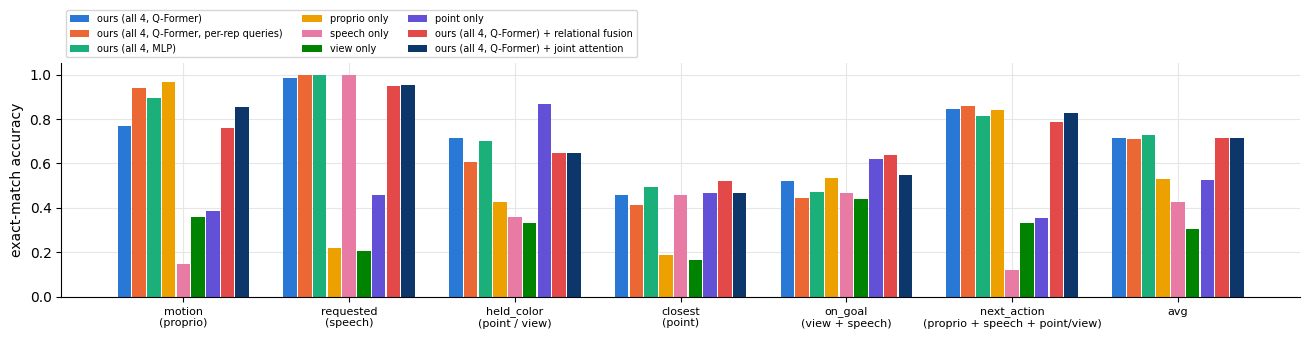

last epoch: auxiliary-head train accuracy per encoder (chance ~0.15) and mean OGM coefficient (1 = not damped)


,aux view,aux point,aux proprio,aux speech,ogm k view,ogm k point,ogm k proprio,ogm k speech
"ours (all 4, Q-Former)",0.30,0.39,0.61,0.66,1.0,1.0,0.76,0.77
"ours (all 4, Q-Former, per-rep queries)",0.36,0.46,0.62,0.72,1.0,1.0,0.84,0.74
"ours (all 4, MLP)",0.33,0.50,0.60,0.79,1.0,1.0,0.91,0.61
proprio only,NaN,NaN,0.65,NaN,NaN,NaN,NaN,NaN
speech only,NaN,NaN,NaN,0.76,NaN,NaN,NaN,NaN
view only,0.34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
point only,NaN,0.64,NaN,NaN,NaN,NaN,NaN,NaN
"ours (all 4, Q-Former) + relational fusion",0.24,0.34,0.59,0.67,1.0,1.0,0.78,0.70
"ours (all 4, Q-Former) + joint attention",0.31,0.35,0.60,0.70,1.0,1.0,0.79,0.70


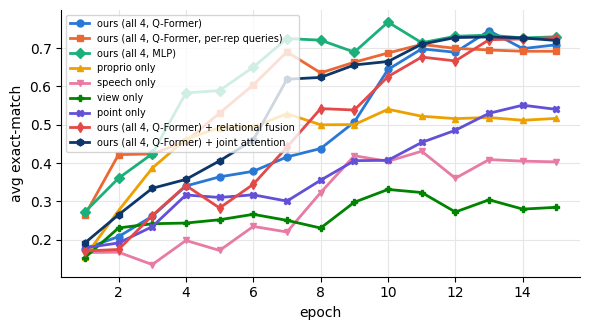

In [33]:
# ---------- Results ----------
import pandas as pd, matplotlib.pyplot as plt
df = pd.DataFrame([r for r in results if r.get("tag") == TAG])
cols = [c for c in ["setting", "budget", "params"] + list(TASKS) + ["avg"] if c in df]
display(df[cols].sort_values("avg", ascending=False).round(3))

# earlier recipes (other TAGs, e.g. the 1M plain-training sweep) next to this one, for the fusion settings
allr = pd.DataFrame([r for r in results if r["setting"].startswith("ours") or r.get("tag") != TAG])
if len(allr) and allr["tag"].nunique() > 1:
    print("all recipes in results_robot.json (tag: _bal1 = balance recipe; budget in params):")
    display(allr[["tag", "budget"] + [c for c in cols if c not in ("budget", "params")]].sort_values(["tag", "avg"], ascending=[True, False]).round(3))

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948", "#0d366b"]
STYLE = {name: dict(color=PALETTE[k % len(PALETTE)], marker="osD^vPXdh"[k % 9]) for k, name in enumerate(SETTINGS)}
def _axes_style(ax):
    ax.grid(True, color="0.9", lw=0.8); ax.set_axisbelow(True)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)

# per-task accuracy: one group per task, one bar per setting (fixed color per setting)
names = [s for s in SETTINGS if s in set(df["setting"])]
fig, ax = plt.subplots(figsize=(1.6 * (len(TASKS) + 1) + 2, 3.6))
xs = np.arange(len(TASKS) + 1); bw = 0.8 / max(len(names), 1)
for j, name in enumerate(names):
    r = df[df["setting"] == name].iloc[-1]
    ax.bar(xs + (j - (len(names) - 1) / 2) * bw, [r[t] for t in list(TASKS) + ["avg"]], bw * 0.92,
           color=STYLE[name]["color"], label=name, hatch="////" if list(SETTINGS).index(name) >= len(PALETTE) else None,
           edgecolor="white", lw=0)
ax.set_xticks(xs, [f"{t}\n({TASKS[t]})" for t in TASKS] + ["avg"], fontsize=8); ax.set_ylim(0, 1.05)
ax.set_ylabel("exact-match accuracy"); _axes_style(ax); ax.legend(fontsize=7, ncol=3, loc="upper left", bbox_to_anchor=(0, 1.25))
plt.tight_layout(); plt.show()

# where the budget went: share of the encoder parameters per representation (runs from 11/22 on record it)
shares = {r["setting"]: {k: v / sum(r["enc_params"].values()) for k, v in r["enc_params"].items()} | {"encoders total": sum(r["enc_params"].values()) / r["params"]}
          for _, r in df.iterrows() if isinstance(r.get("enc_params"), dict) and len(r["enc_params"]) > 1}
if shares:
    print("encoder parameter shares (and encoders' share of all trainable parameters)"); display(pd.DataFrame(shares).T.round(2))

# balance recipe diagnostics: does each encoder learn on its own (aux head train acc), and how much was it damped?
aux_rows = {r["setting"]: {f"aux {k}": v for k, v in r["curve"][-1].get("aux_train_acc", {}).items()}
            | {f"ogm k {k}": v for k, v in r["curve"][-1].get("ogm_k", {}).items()} for _, r in df.iterrows()}
if any(aux_rows.values()):
    print("last epoch: auxiliary-head train accuracy per encoder (chance ~0.15) and mean OGM coefficient (1 = not damped)")
    display(pd.DataFrame(aux_rows).T.round(2))

# learning curves (avg accuracy on the first curve_n test examples after each epoch)
fig, ax = plt.subplots(figsize=(6, 3.4))
for _, r in df.iterrows():
    ax.plot([c["epoch"] for c in r["curve"]], [c["avg"] for c in r["curve"]], lw=2, ms=5, label=r["setting"], **STYLE[r["setting"]])
ax.set_xlabel("epoch"); ax.set_ylabel("avg exact-match"); _axes_style(ax); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()


## 9. Router: which representations does each question need?
Same procedure as sections 11–13 of `multirep_adaptor_harder3d.ipynb`, but without an extra training stage: the sweep's fusion models were already trained with per-representation dropout (balance recipe), so they run with any subset of their encoders. The one that is routed is the best fusion model **on the router split** (printed), never chosen on test.

1. **Router split.** 100 fresh episodes (another seed) → 1,200 examples, 200 per task; the sweep's training set and the test set are untouched (~2–3 min of CPU generation, cached in `robot_router_<data>_s<seed>.pkl`).
2. **Score every subset.** The frozen adaptor answers every router-split and test example with each of the **15 non-empty subsets** of {view, point, proprio, speech} (per-example answer loss + exact match; ~5 min on a T4, cached in `stages_robot.json`). → robustness table.
3. **Train the router.** A tiny MLP reads only the question (mean of its frozen LLM token embeddings), never the scene, and picks a subset, so routed-out encoders are never run. Target: soft-min over subsets of *loss + λ·cost* on the router split; cost = share of encoder parameters run. λ ∈ {0, 0.1, 0.3, 1, 3}; λ\* = the cheapest router within 1 point of the best accuracy **on the router split** (test is never used for choosing). Prints which subset each task is routed to: the task design predicts motion → proprio, requested → speech.


In [34]:
# ---------- 9. Router: which representations does this question need? (no extra adaptor training) ----------
# Stage 1 = the sweep's best "ours" model (chosen on the router split), trained with per-representation dropout
# (CFG["balance"]), so it runs with any subset of its encoders. Router data = fresh episodes (another seed): the sweep's training set and the
# test set stay untouched. Needs sections 3-7b.
from itertools import combinations
import pickle, pandas as pd
ROUTE_BUDGET = BUDGETS[0]
ROUTER_EPS, ROUTER_N = 100, 1200                     # held-out episodes / examples (200 per task) for the router
SUBSETS = [s for k in range(1, len(ALL) + 1) for s in combinations(ALL, k)]   # the 15 non-empty subsets
SUB_NAMES = ["+".join(s) for s in SUBSETS]
LAMBDAS, ROUTER_TAU = [0.0, 0.1, 0.3, 1.0, 3.0], 0.3
STAGES_PATH = "stages_robot.json"

if not CFG.get("balance"):
    print("WARNING: the routed model was trained without representation dropout; subsets other than all 4 are "
          "out of distribution for it, so the router numbers below are pessimistic.")
ROUTER_DATA_PATH = f"robot_router_{CFG['data']}_s{CFG['seed']}.pkl"
if os.path.exists(ROUTER_DATA_PATH):
    router_data, router_eps = pickle.load(open(ROUTER_DATA_PATH, "rb")); print("loaded", ROUTER_DATA_PATH)
else:
    SIM = globals().get("SIM") or make_sim()
    print("router split:"); router_data, router_eps = build_split(ROUTER_EPS, ROUTER_N // len(TASKS), CFG["seed"] + 2, SIM)
    pickle.dump((router_data, router_eps), open(ROUTER_DATA_PATH, "wb"))
if ensure_view_res(router_data, router_eps): save_pickle((router_data, router_eps), ROUTER_DATA_PATH)   # 64 px cache

stages = json.load(open(STAGES_PATH)) if os.path.exists(STAGES_PATH) else {}
stages = stages if stages.get("tag") == TAG else {"tag": TAG}
# which fusion model to route: the best "ours" on the router split (a validation set; test is never used to choose)
trained = {r["setting"] for r in results if r.get("tag") == TAG and r["budget"] == ROUTE_BUDGET and os.path.exists(r.get("ckpt", ""))}
cands = sorted(s for s in SETTINGS if s.startswith("ours") and s in trained)
if stages.get("route_cands") != cands:                    # new fusion models trained since -> choose again
    val = {s: evaluate(load_run(s, ROUTE_BUDGET), router_data)["avg"] for s in cands}
    best_s = max(val, key=val.get)
    if best_s != stages.get("route_setting"):
        for k in ("subsets", "router", "final", "lambda_star"): stages.pop(k, None)   # scores of the old model are stale
    stages.update(route_setting=best_s, route_val=val, route_cands=cands)
    json.dump(stages, open(STAGES_PATH, "w"))
ROUTE_SETTING = stages["route_setting"]
print("router-split accuracy of the fusion models:", {k: round(v, 3) for k, v in stages["route_val"].items()}, "->", ROUTE_SETTING)
route_model = load_run(ROUTE_SETTING, ROUTE_BUDGET)

@torch.no_grad()
def subset_scores(model, data, subsets=SUBSETS, bs=64):
    """For every example and every subset of representations: summed answer-token loss (nats) and teacher-forced
    exact match. The other representations are masked out of the Q-Former's cross-attention."""
    model.eval(); n = len(data); L = np.zeros((n, len(subsets))); C = np.zeros((n, len(subsets)), bool)
    for s0 in range(0, n, bs):
        b = to_dev(collate(data[s0:s0 + bs])); B = len(b["ids"])
        for j, sub in enumerate(subsets):
            drop = torch.tensor([r not in sub for r in model.reps], device=device).expand(B, -1)
            logits, tgt, ex = answer_logits(model, b, drop)
            ce = F.cross_entropy(logits, tgt, reduction="none")
            L[s0:s0 + B, j] = torch.zeros(B, device=device).index_add_(0, ex, ce).cpu().numpy()
            C[s0:s0 + B, j] = (torch.zeros(B, device=device).index_add_(0, ex, (logits.argmax(-1) != tgt).float()) == 0).cpu().numpy()
    return L, C

def per_task(correct, data):
    t = np.array([ex["task"] for ex in data]); res = {k: float(correct[t == k].mean()) for k in TASKS}
    res["avg"] = float(np.mean(list(res.values()))); return res

if "subsets" not in stages:
    t0 = time.time()
    L_router, C_router = subset_scores(route_model, router_data); L_test, C_test = subset_scores(route_model, test_data)
    stages["subsets"] = dict(L_router=L_router.tolist(), C_router=C_router.tolist(), L_test=L_test.tolist(), C_test=C_test.tolist())
    json.dump(stages, open(STAGES_PATH, "w")); print(f"scored {len(SUBSETS)} subsets in {time.time() - t0:.0f}s")
L_router, C_router = np.array(stages["subsets"]["L_router"]), np.array(stages["subsets"]["C_router"], bool)
L_test, C_test = np.array(stages["subsets"]["L_test"]), np.array(stages["subsets"]["C_test"], bool)
rob = pd.DataFrame({name: per_task(C_test[:, j], test_data) for j, name in enumerate(SUB_NAMES)}).T
print("robustness: the same adaptor, given only these representations at test time"); display(rob.round(2))

# ---- router: question only (mean of its frozen LLM token embeddings) -> subset. It never sees the scene, so a
# routed-out encoder is never run. Target: soft-min over subsets of loss + lambda * cost on the router split.
ENC_PARAMS = {r: n_params(route_model.enc[r]) + (n_params(route_model.proj[r]) if r in route_model.proj else 0) for r in ALL}
COST = np.array([sum(ENC_PARAMS[r] for r in s) for s in SUBSETS]) / sum(ENC_PARAMS.values())   # share of encoder params run
print("encoder params:", {r: f"{v / 1e3:.0f}k" for r, v in ENC_PARAMS.items()})

@torch.no_grad()
def question_feats(data):
    ids = [torch.tensor(tok(f"Question: {ex['q']} Answer:", add_special_tokens=False)["input_ids"], device=device) for ex in data]
    return torch.stack([embed(i).float().mean(0) for i in ids])

class Router(nn.Module):
    def __init__(self, d_in, n_out, h=128):
        super().__init__(); self.net = nn.Sequential(nn.LayerNorm(d_in), nn.Linear(d_in, h), nn.GELU(), nn.Linear(h, n_out))
    def forward(self, x): return self.net(x)

def train_router(X, L, lam, steps=400, lr=3e-3, seed=0):
    torch.manual_seed(seed)
    target = torch.softmax(-(torch.tensor(L, device=device, dtype=torch.float)
                             + lam * torch.tensor(COST, device=device, dtype=torch.float)) / ROUTER_TAU, -1)
    router = Router(X.size(1), len(SUBSETS)).to(device); opt = torch.optim.AdamW(router.parameters(), lr=lr, weight_decay=0.01)
    for _ in range(steps):
        loss = -(target * F.log_softmax(router(X), -1)).sum(-1).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    return router.eval()

def routed(C, pick, data):
    res = per_task(C[np.arange(len(C)), pick], data); res["cost"] = float(COST[pick].mean())
    res["n_reps"] = float(np.mean([len(SUBSETS[j]) for j in pick])); return res

X_router, X_test = question_feats(router_data), question_feats(test_data)
router_rows = {}
for lam in LAMBDAS:
    rt = train_router(X_router, L_router, lam)
    with torch.no_grad(): pick_r, pick_t = rt(X_router).argmax(-1).cpu().numpy(), rt(X_test).argmax(-1).cpu().numpy()
    router_rows[lam] = dict(router_split=routed(C_router, pick_r, router_data), test=routed(C_test, pick_t, test_data), pick_test=pick_t.tolist())
    print(f"lambda {lam:<4}: router split avg {router_rows[lam]['router_split']['avg']:.3f} | test avg "
          f"{router_rows[lam]['test']['avg']:.3f}, encoder cost {router_rows[lam]['test']['cost']:.2f}, "
          f"{router_rows[lam]['test']['n_reps']:.2f} reps/question")
best = max(v["router_split"]["avg"] for v in router_rows.values())
LAM_STAR = max(l for l, v in router_rows.items() if v["router_split"]["avg"] >= best - 0.01)   # chosen on the router split
stages["router"] = {str(k): v for k, v in router_rows.items()}; stages["lambda_star"] = LAM_STAR
json.dump(stages, open(STAGES_PATH, "w"))
pick = np.array(router_rows[LAM_STAR]["pick_test"]); tasks_arr = np.array([ex["task"] for ex in test_data])
choice = pd.DataFrame([[np.mean(pick[tasks_arr == t] == j) for j in range(len(SUBSETS))] for t in TASKS], index=list(TASKS), columns=SUB_NAMES)
choice = choice.loc[:, choice.sum() > 0]                  # only subsets the router ever picks
print(f"lambda* = {LAM_STAR} (cheapest within 1 point of the best router-split accuracy). Router choices on test:")
display(choice.round(2))


loaded robot_router_robot_v1_s0.pkl
router-split accuracy of the fusion models: {'ours (all 4, MLP)': 0.691, 'ours (all 4, Q-Former)': 0.685, 'ours (all 4, Q-Former) + joint attention': 0.664, 'ours (all 4, Q-Former) + relational fusion': 0.667, 'ours (all 4, Q-Former, per-rep queries)': 0.701} -> ours (all 4, Q-Former, per-rep queries)
robustness: the same adaptor, given only these representations at test time


,motion,requested,held_color,closest,on_goal,next_action,avg
view,0.21,0.17,0.33,0.15,0.39,0.29,0.26
point,0.36,0.31,0.36,0.25,0.62,0.32,0.37
proprio,0.89,0.13,0.45,0.19,0.54,0.84,0.51
speech,0.26,1.00,0.43,0.38,0.41,0.13,0.44
view+point,0.35,0.29,0.37,0.25,0.57,0.35,0.36
view+proprio,0.90,0.18,0.45,0.18,0.45,0.83,0.50
view+speech,0.27,1.00,0.43,0.38,0.41,0.23,0.45
point+proprio,0.94,0.27,0.56,0.23,0.56,0.85,0.57
point+speech,0.37,1.00,0.45,0.41,0.45,0.35,0.51
proprio+speech,0.91,1.00,0.61,0.38,0.41,0.83,0.69


encoder params: {'view': '507k', 'point': '77k', 'proprio': '226k', 'speech': '412k'}
lambda 0.0 : router split avg 0.667 | test avg 0.662, encoder cost 0.55, 2.50 reps/question
lambda 0.1 : router split avg 0.665 | test avg 0.668, encoder cost 0.24, 1.33 reps/question
lambda 0.3 : router split avg 0.665 | test avg 0.668, encoder cost 0.24, 1.33 reps/question
lambda 1.0 : router split avg 0.644 | test avg 0.693, encoder cost 0.18, 1.17 reps/question
lambda 3.0 : router split avg 0.622 | test avg 0.676, encoder cost 0.17, 1.00 reps/question
lambda* = 0.3 (cheapest within 1 point of the best router-split accuracy). Router choices on test:


,point,proprio,speech,point+proprio
motion,0.0,0.0,0.0,1.0
requested,0.0,0.0,1.0,0.0
held_color,0.0,0.0,0.0,1.0
closest,1.0,0.0,0.0,0.0
on_goal,0.0,0.0,1.0,0.0
next_action,0.0,1.0,0.0,0.0


## 10. Final table and figures
Dedicated single-rep models and ours-MLP from the sweep, ours with all 4, the best single subset of the same model, the router at λ\*, and oracle routing (the cheapest subset that answers correctly: an upper bound). Saves `fig_robot_router_frontier.png` (accuracy vs. encoder cost) and `fig_robot_robustness.png` (each task under each subset); `bundle()` in 7b includes them.


Final (test, 2M trainable params everywhere; cost = share of the routed model's encoder parameters run per question)


,motion,requested,held_color,closest,on_goal,next_action,avg,cost,n_reps
"ours (all 4, Q-Former) (dedicated)",0.767,0.987,0.713,0.460,0.520,0.847,0.716,NaN,NaN
"ours (all 4, MLP) (dedicated)",0.893,1.000,0.700,0.493,0.473,0.813,0.729,NaN,NaN
proprio only (dedicated),0.967,0.220,0.427,0.187,0.533,0.840,0.529,NaN,NaN
speech only (dedicated),0.147,1.000,0.360,0.460,0.467,0.120,0.426,NaN,NaN
view only (dedicated),0.360,0.207,0.333,0.167,0.440,0.333,0.307,NaN,NaN
point only (dedicated),0.387,0.460,0.867,0.467,0.620,0.353,0.526,NaN,NaN
"ours (all 4, Q-Former) + relational fusion (dedicated)",0.760,0.947,0.647,0.520,0.640,0.787,0.717,NaN,NaN
"ours (all 4, Q-Former) + joint attention (dedicated)",0.853,0.953,0.647,0.467,0.547,0.827,0.716,NaN,NaN
"ours (all 4, Q-Former, per-rep queries): all 4",0.940,1.000,0.607,0.413,0.447,0.860,0.711,1.000,4.000
"same model, proprio only",0.887,0.133,0.453,0.187,0.540,0.840,0.507,0.185,1.000


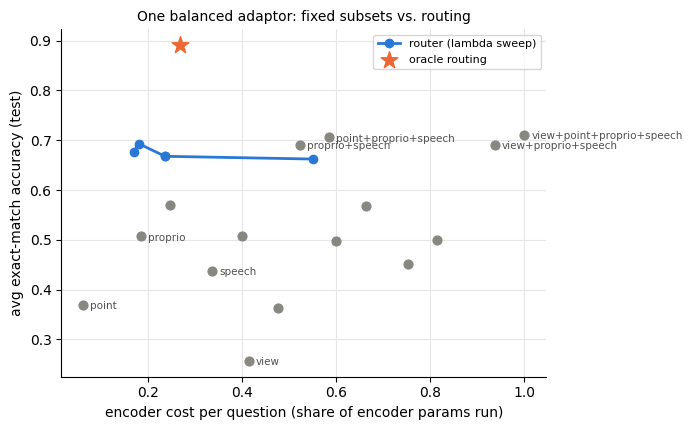

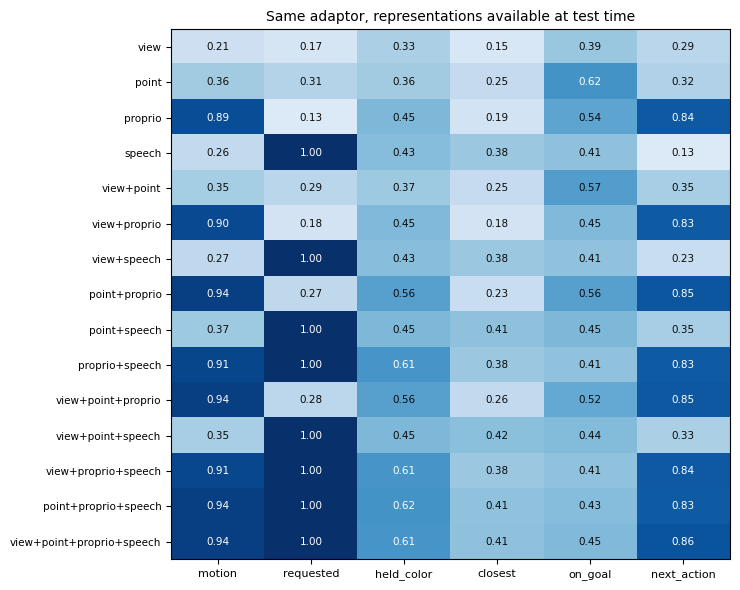

saved stages_robot.json, fig_robot_router_frontier.png, fig_robot_robustness.png


In [35]:
# ---------- 10. Final table and figures ----------
full = SUB_NAMES.index("+".join(ALL))
oracle_pick = np.where(C_test.any(1), np.argmax(C_test / (1 + COST), 1), full)   # cheapest subset that is right, if any
ded = {r["setting"]: r for r in results if r.get("tag") == TAG and r["budget"] == ROUTE_BUDGET}
rows = {}
for name in SETTINGS:
    if name in ded and name != ROUTE_SETTING: rows[f"{name} (dedicated)"] = {k: ded[name][k] for k in list(TASKS) + ["avg"]}
rows[f"{ROUTE_SETTING}: all 4"] = routed(C_test, np.full(len(test_data), full), test_data)
singles = [j for j, s in enumerate(SUBSETS) if len(s) == 1]
bs = max(singles, key=lambda j: per_task(C_test[:, j], test_data)["avg"])
rows[f"  same model, {SUB_NAMES[bs]} only"] = routed(C_test, np.full(len(test_data), bs), test_data)
rows[f"  same model + router (lambda* = {LAM_STAR})"] = router_rows[LAM_STAR]["test"]
rows["oracle routing (upper bound)"] = routed(C_test, oracle_pick, test_data)
final = pd.DataFrame(rows).T.reindex(columns=list(TASKS) + ["avg", "cost", "n_reps"])
print(f"Final (test, {ROUTE_BUDGET / 1e6:g}M trainable params everywhere; cost = share of the routed model's encoder "
      "parameters run per question)"); display(final.round(3))
stages["final"] = {k: {kk: (None if isinstance(vv, float) and np.isnan(vv) else vv) for kk, vv in v.items()} for k, v in rows.items()}
json.dump(stages, open(STAGES_PATH, "w"))

def _style(ax):
    ax.grid(True, color="0.9", lw=0.8); ax.set_axisbelow(True)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)

# accuracy vs encoder cost: fixed subsets of the one model (gray), the router frontier (blue), oracle (star)
fig, ax = plt.subplots(figsize=(7, 4.4))
for j, s in enumerate(SUBSETS):
    r = routed(C_test, np.full(len(test_data), j), test_data)
    ax.scatter(r["cost"], r["avg"], s=40, color="#898781", zorder=3)
    if len(s) in (1, len(ALL)) or r["avg"] >= rob["avg"].max() - 0.03:   # label singles, all 4 and the best ones
        ax.annotate(SUB_NAMES[j], (r["cost"], r["avg"]), xytext=(5, -3), textcoords="offset points", fontsize=7.5, color="#52514e")
rt_ = [router_rows[l]["test"] for l in LAMBDAS]
ax.plot([r["cost"] for r in rt_], [r["avg"] for r in rt_], "-o", color="#2a78d6", lw=2, ms=6, label="router (lambda sweep)", zorder=4)
o = rows["oracle routing (upper bound)"]; ax.scatter(o["cost"], o["avg"], marker="*", s=160, color="#eb6834", label="oracle routing", zorder=5)
ax.set_xlabel("encoder cost per question (share of encoder params run)"); ax.set_ylabel("avg exact-match accuracy (test)")
ax.set_title("One balanced adaptor: fixed subsets vs. routing", fontsize=10); ax.legend(fontsize=8); _style(ax)
plt.tight_layout(); plt.savefig("fig_robot_router_frontier.png", dpi=200); plt.show()

# robustness: each task under each subset (same model)
fig, ax = plt.subplots(figsize=(7.5, 6))
M = rob.loc[SUB_NAMES, list(TASKS)].values.astype(float)
ax.imshow(M, cmap="Blues", vmin=0, vmax=1, aspect="auto")
for i in range(M.shape[0]):
    for j in range(M.shape[1]): ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=7.5, color="white" if M[i, j] > 0.6 else "#0b0b0b")
ax.set_xticks(range(len(TASKS)), list(TASKS), fontsize=8); ax.set_yticks(range(len(SUB_NAMES)), SUB_NAMES, fontsize=7.5)
ax.set_title("Same adaptor, representations available at test time", fontsize=10)
plt.tight_layout(); plt.savefig("fig_robot_robustness.png", dpi=200); plt.show()
print("saved stages_robot.json, fig_robot_router_frontier.png, fig_robot_robustness.png")


## 11. Demo: a new episode, answered live
Pick the spoken color, the robot's mistake (`none` / `missed` grasp / `wrong` cube) and whether a distractor cube sits on the goal in `DEMO`. A brand-new episode is generated and the instruction is synthesized (it is played below and muxed into the video). The adaptor routed in section 9 then answers every question that has a ground truth at each frame by **free greedy generation** from the frozen LLM (no teacher forcing). With `routed=True`, each question only runs the encoders the router picks at λ\* (the filled dots). Left: the scene (high-res, for humans) and exactly what the encoders receive. Right: the six questions with the model's answer, ✓ / ✗ against the ground truth, and which encoders were run. Writes `demo_robot.mp4` (a GIF without ffmpeg) and `fig_robot_demo.png` (4 key frames, for slides). Takes ~1 min on a T4. Change `DEMO` and re-run the cell for another episode.


In [ ]:
# ---------- 11. Demo: a brand-new episode, the routed adaptor answering every frame ----------
# Pick the spoken color and what goes wrong; the robot runs, the spoken instruction is synthesized, and the section-9
# fusion model (+ its router at lambda*) answers every question that has a ground truth at each frame, by greedy
# decoding from the frozen LLM. Output: demo_robot.mp4 (with the spoken instruction as audio, if ffmpeg is there),
# shown inline, and fig_robot_demo.png (4 key frames, for slides). Needs sections 3-9 (route_model, router split).
from matplotlib import animation, patches
from IPython.display import Audio, HTML, display
import base64, subprocess

DEMO = dict(color="blue",            # requested color: red / orange / yellow / blue / purple / pink
            mistake="wrong",         # "none" | "missed" (grasp fails, carries nothing) | "wrong" (picks another cube)
            distractor=False,        # another cube already sits on the goal
            seed=2026,               # layout, motion and voice
            routed=True,             # True: each question runs only the encoders the router picks; False: all 4
            every=1)                 # answer every n-th frame (1 = all, 12 FPS)
assert DEMO["color"] in COLORS and DEMO["mistake"] in ("none", "missed", "wrong")
REP_COLOR = {"view": "#2a78d6", "point": "#eb6834", "proprio": "#6250d6", "speech": "#e87ba4"}
REP_SHORT = {"view": "view", "point": "points", "proprio": "proprio", "speech": "speech"}
GOOD, BAD, MUTED, INK = "#1baf7a", "#e34948", "#9a9893", "#1f1e1c"

def demo_episode(color, mistake, distractor, seed):
    S = globals().get("SIM") or make_sim(); globals()["SIM"] = S
    keep = {k: CFG[k] for k in ("p_fail", "p_wrong", "p_distractor")}
    CFG.update(p_fail=float(mistake == "missed"), p_wrong=float(mistake == "wrong"), p_distractor=float(distractor))
    try: ep = gen_episode_ok(S, np.random.default_rng(seed))
    finally: CFG.update(keep)
    if color in ep["colors"]: ep["colors"][ep["colors"].index(color)] = ep["colors"][0]   # colors do not affect motion
    ep["colors"][0] = color
    rng = np.random.default_rng(seed + 1)
    text = str(rng.choice(TEMPLATES)).format(color); wav = tts(text, rng); ep["mel"] = log_mel(wav)
    return S, ep, text, wav

def demo_example(ep, k, task, a, views, pts, prgb):
    lo = max(0, k - WIN + 1); win = np.r_[[0] * (WIN - (k - lo + 1)), np.arange(lo, k + 1)].astype(int)
    return dict(task=task, q=QUESTIONS[task], a=a, ep=0, k=k, views=views, points=pts, point_rgb=prgb,
                proprio=np.c_[ep["q"][win], ep["finger"][win], ep["ee"][win]].astype(np.float32), speech=ep["mel"])

@torch.no_grad()
def greedy_answers(model, exs, drop_reps=(), max_new=6):
    """Free generation (no ground truth used): soft tokens + question -> frozen LLM, greedy, until EOS.
    All examples share one question, so the prompts have equal length (no padding)."""
    model.eval(); b = to_dev(collate(exs)); assert not b["q_pad"].any()
    if model.q_cond: b["q_emb"] = embed(b["q_ids"])
    drop = torch.tensor([r in drop_reps for r in model.reps], device=device).expand(len(exs), -1)
    with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
        x = torch.cat([model(b, drop), embed(b["q_ids"])], 1); out = []
        for _ in range(max_new):
            nxt = llm.lm_head(llm.model(inputs_embeds=x).last_hidden_state[:, -1]).argmax(-1)
            out.append(nxt); x = torch.cat([x, embed(nxt)[:, None]], 1)
    out = torch.stack(out, 1).tolist()
    return [tok.decode(o[:o.index(EOS)] if EOS in o else o).strip() for o in out]

# ---- episode, frames, answers
t0 = time.time()
SIM, demo_ep, demo_text, demo_wav = demo_episode(DEMO["color"], DEMO["mistake"], DEMO["distractor"], DEMO["seed"])
demo_T = demo_ep["T"]; frames = list(range(0, demo_T, DEMO["every"]))
truth = {(task, k): a for task, k, a, _ in _candidates(demo_ep)}
HI = 360; hi_view = p.computeViewMatrix(*CAMS["front"], [0, 0, 1])
inputs, hi_imgs = {}, {}
for k in frames:
    inputs[k] = render(SIM, demo_ep, k, np.random.default_rng([DEMO["seed"], k]))   # exactly what the model gets
    hi_imgs[k] = np.asarray(p.getCameraImage(HI, HI, hi_view, SIM["proj"], renderer=p.ER_TINY_RENDERER)[2], np.uint8).reshape(HI, HI, 4)[..., :3]
print(f"episode {demo_T / FPS:.1f}s ({demo_T} frames), rendered in {time.time() - t0:.0f}s | instruction: \"{demo_text}\"")

if DEMO["routed"] and "LAM_STAR" in globals():
    router_star = train_router(X_router, L_router, LAM_STAR)              # = section 9's router at lambda*
    with torch.no_grad():
        rpick = router_star(question_feats([dict(q=QUESTIONS[t]) for t in TASKS])).argmax(-1).tolist()
    use = {t: SUBSETS[j] for t, j in zip(TASKS, rpick)}
else:
    use = {t: tuple(route_model.reps) for t in TASKS}
print("encoders per question:", {t: "+".join(s) for t, s in use.items()})
answers = {}
for task in TASKS:
    ks = [k for k in frames if (task, k) in truth]
    for s0 in range(0, len(ks), 64):
        chunk = ks[s0:s0 + 64]
        exs = [demo_example(demo_ep, k, task, truth[task, k], *inputs[k]) for k in chunk]
        preds = greedy_answers(route_model, exs, drop_reps=tuple(r for r in route_model.reps if r not in use[task]))
        answers.update({(task, k): pr for k, pr in zip(chunk, preds)})
hits = {t: [answers[t, k] == truth[t, k] for k in frames if (t, k) in answers] for t in TASKS}
demo_cost = {t: sum(ENC_PARAMS[r] for r in use[t]) / sum(ENC_PARAMS.values()) for t in TASKS}
print("accuracy over this episode:", {t: f"{np.mean(h):.2f} ({len(h)})" for t, h in hits.items() if h},
      f"| overall {np.mean(sum(hits.values(), [])):.2f}")
display(Audio(demo_wav, rate=SR))

# ---- figure: live scene + model inputs (left), the six questions (right)
plt.rcParams["font.family"] = "DejaVu Sans"
fig = plt.figure(figsize=(12.8, 7.2), dpi=100, facecolor="white")
ax_hi = fig.add_axes([0.01, 0.30, 0.42, 0.62]); ax_hi.axis("off")
im_hi = ax_hi.imshow(hi_imgs[frames[0]])
title = fig.text(0.015, 0.955, "", fontsize=13, weight="bold", color=INK)
fig.text(0.015, 0.925, f"Robot told (audio only): \"{demo_text}\"   |   "
         + {"none": "robot executes correctly", "missed": "robot MISSES the grasp",
            "wrong": "robot picks the WRONG cube"}[DEMO["mistake"]]
         + ("   |   distractor cube on the goal" if DEMO["distractor"] else ""), fontsize=9.5, color="#52514e")
small = [fig.add_axes([0.012 + i * 0.108, 0.035, 0.1, 0.2]) for i in range(4)]
ims = [small[c].imshow(inputs[frames[0]][0][c]) for c in range(2)]
for c, cam in enumerate(CAMS): small[c].set_title(f"{cam} camera ({inputs[frames[0]][0].shape[1]} px)", fontsize=7.5)
pc0 = inputs[frames[0]][1] * PC_SCALE + PC_CENTER
sc = small[2].scatter(pc0[:, 0], pc0[:, 1], c=inputs[frames[0]][2], s=2); small[2].set_title("point cloud (top view)", fontsize=7.5)
small[2].set_xlim(0.15, 0.75); small[2].set_ylim(-0.35, 0.35); small[2].invert_xaxis()
small[3].imshow(demo_ep["mel"].T, origin="lower", aspect="auto", cmap="magma"); small[3].set_title("speech (log-mel)", fontsize=7.5)
ax_pr = fig.add_axes([0.45, 0.035, 0.12, 0.2])
tt = np.arange(demo_T) / FPS
for i, (lbl, col) in enumerate(zip("xyz", ["#2a78d6", "#eb6834", "#1baf7a"])): ax_pr.plot(tt, demo_ep["ee"][:, i], color=col, lw=1, label=lbl)
cursor = ax_pr.axvline(0, color=INK, lw=1); ax_pr.set_title("proprio: gripper xyz", fontsize=7.5); ax_pr.legend(fontsize=6, loc="upper right")
ax_pr.tick_params(labelsize=6)
for a in small: a.set_xticks([]); a.set_yticks([])

# question panel
ax_q = fig.add_axes([0.6, 0.03, 0.39, 0.89]); ax_q.axis("off"); ax_q.set_xlim(0, 1); ax_q.set_ylim(0, 1)
ax_q.text(0, 0.985, f"Frozen Qwen2.5-0.5B + adaptor ({ROUTE_SETTING})", fontsize=8, color="#52514e", va="top")
q_rows = {}
for i, t in enumerate(TASKS):
    y = 0.9 - i * 0.145
    ax_q.add_patch(patches.FancyBboxPatch((0, y - 0.11), 1, 0.125, boxstyle="round,pad=0.004,rounding_size=0.01",
                                          fc="#f5f4f1", ec="none"))
    ax_q.text(0.02, y, QUESTIONS[t], fontsize=9.5, color=INK, va="center")
    lights = []
    for j, r in enumerate(ALL):
        on = r in use[t]
        ax_q.add_patch(patches.Circle((0.035 + j * 0.13, y - 0.075), 0.011, fc=REP_COLOR[r] if on else "white",
                                      ec=REP_COLOR[r], lw=1.2))
        ax_q.text(0.055 + j * 0.13, y - 0.075, REP_SHORT[r], fontsize=7, va="center", color=INK if on else MUTED)
    ans = ax_q.text(0.6, y - 0.045, "", fontsize=13, weight="bold", va="center")
    mark = ax_q.text(0.97, y - 0.045, "", fontsize=16, weight="bold", va="center", ha="right")
    tru = ax_q.text(0.6, y - 0.09, "", fontsize=7.5, va="center", color="#52514e")
    q_rows[t] = (ans, mark, tru)
score = ax_q.text(0, 0.0, "", fontsize=9, color=INK, va="bottom", linespacing=1.5)

def draw(k):
    im_hi.set_data(hi_imgs[k]); v, pts, prgb = inputs[k]
    for c in range(2): ims[c].set_data(v[c])
    P = pts * PC_SCALE + PC_CENTER; sc.set_offsets(P[:, :2]); sc.set_facecolors(prgb)
    cursor.set_xdata([k / FPS])
    title.set_text(f"t = {k / FPS:4.1f} s    phase: {PHASES[demo_ep['phase'][k]]}")
    for t, (ans, mark, tru) in q_rows.items():
        if (t, k) in answers:
            ok = answers[t, k] == truth[t, k]
            ans.set_text(answers[t, k] or "(empty)"); ans.set_color(INK); ans.set_fontsize(13)
            mark.set_text("✓" if ok else "✗"); mark.set_color(GOOD if ok else BAD)
            tru.set_text(f"truth: {truth[t, k]}   ({'correct' if ok else 'wrong'})")
        else:                                                   # no ground truth in this phase -> not asked
            ans.set_text("not asked now"); ans.set_color(MUTED); ans.set_fontsize(9); mark.set_text(""); tru.set_text("")
    done = [answers[t, kk] == truth[t, kk] for t in TASKS for kk in frames if kk <= k and (t, kk) in answers]
    score.set_text(f"so far: {sum(done)}/{len(done)} answers correct\nencoders run per question: "
                   f"{np.mean([demo_cost[t] for t in TASKS for kk in frames if kk <= k and (t, kk) in answers] or [0]):.0%} of encoder params")
    return []

draw(frames[0])
anim = animation.FuncAnimation(fig, lambda i: draw(frames[i]), frames=len(frames), interval=1000 * DEMO["every"] / FPS)
OUT = "demo_robot.mp4"
if animation.writers.is_available("ffmpeg"):
    anim.save("demo_robot_silent.mp4", writer=animation.FFMpegWriter(fps=FPS / DEMO["every"], bitrate=3000))
    wavfile.write("demo_speech.wav", SR, (np.clip(demo_wav, -1, 1) * 32767).astype(np.int16))
    r = subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", "demo_robot_silent.mp4", "-i", "demo_speech.wav",
                        "-c:v", "copy", "-c:a", "aac", OUT], capture_output=True)
    if r.returncode != 0: os.replace("demo_robot_silent.mp4", OUT)           # no audio track then
    display(HTML(f'<video width="960" controls autoplay><source src="data:video/mp4;base64,'
                 f'{base64.b64encode(open(OUT, "rb").read()).decode()}" type="video/mp4"></video>'))
else:
    OUT = "demo_robot.gif"; anim.save(OUT, writer=animation.PillowWriter(fps=FPS / DEMO["every"]))
    display(HTML(f'<img src="data:image/gif;base64,{base64.b64encode(open(OUT, "rb").read()).decode()}" width="960">'))
print("saved", OUT, f"({os.path.getsize(OUT) / 1e6:.1f} MB)")

# ---- static strip for slides: one frame per stage of the episode
key_phases = ["approach", "lift", "carry", "retract"]
key = [next((k for k in frames if PHASES[demo_ep["phase"][k]] == ph), frames[0]) for ph in key_phases[:-1]] + [frames[-1]]
shots = []
for k in key:
    draw(k); fig.canvas.draw(); shots.append(np.asarray(fig.canvas.buffer_rgba())[..., :3].copy())
plt.close(fig)
fig2, axs = plt.subplots(2, 2, figsize=(16, 9.2))
for a, s in zip(axs.ravel(), shots): a.imshow(s); a.axis("off")
plt.tight_layout(); plt.savefig("fig_robot_demo.png", dpi=150); plt.show()
print("saved fig_robot_demo.png")
